# <u><font color=#000080>Project Overview</font></u>


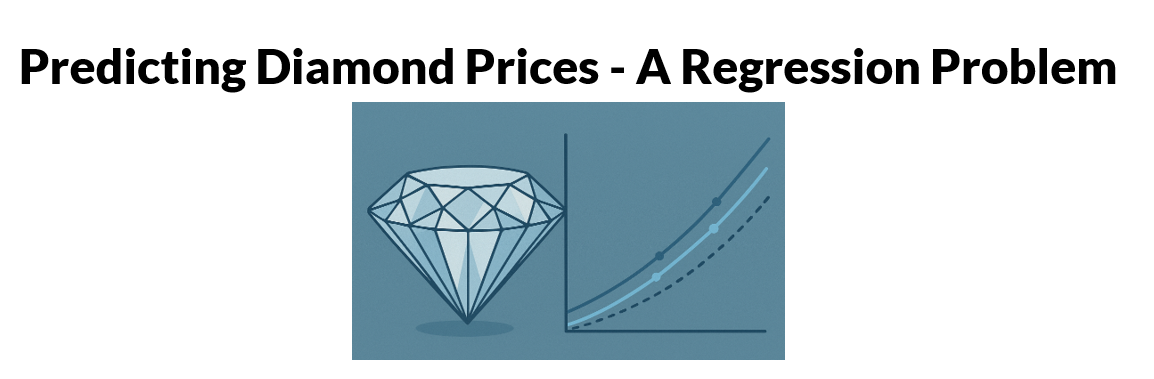

Accurate diamond price prediction can support more consistent pricing and improve transparency in diamond marketplaces.

This project encompassed building a robust and interpretable model for predicting diamond prices by understanding the interplay of key quality indicators(`cut`, `color`, `clarity`) and physical characteristics (`carat`, `depth`, `table`, and dimensions).

Using the <b>diamond_prices dataset</b>, which contains <b>53,943 observations</b>, we applied a structured workflow involving data validation, exploratory analysis, statistical testing, feature engineering, model comparison, hyperparameter optimization, and model interpretation.

The objective was to identify the most influential pricing factors and develop an accurate, interpretable predictive model supported by the available data.

This approach aims to improve predictive accuracy while providing interpretable insights into how models use different features to predict diamond prices.




# <u><font color=#000080>1. About the data</font></u>




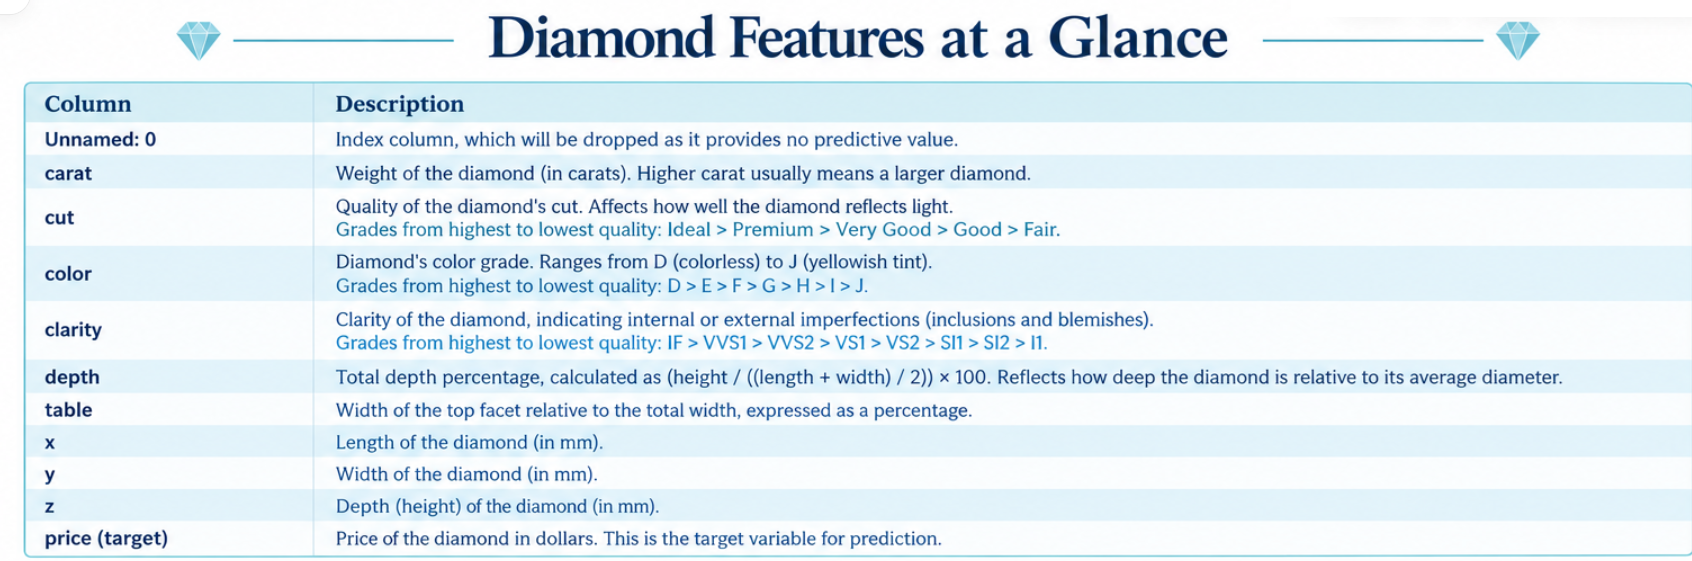

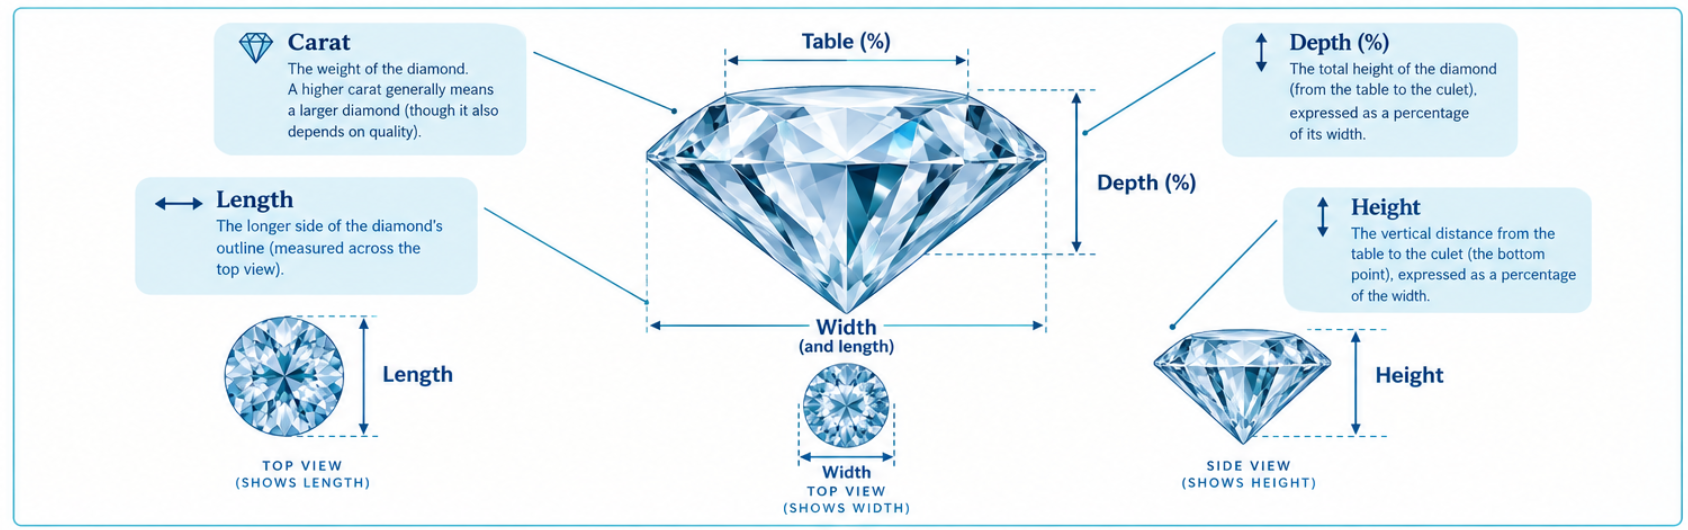

# <u><font color=#000080>2. Load Packages and Dependencies</font></u>

In [4]:
%%capture
# Install packages that are not included in the default envronment
!pip install category_encoders
!pip install optuna


In [5]:
# Core data manipulation and visualization libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis and utility libraries
import scipy.stats as stats
from itertools import combinations
from scipy.stats import chi2_contingency # Chi-squared test

# Statsmodels for advanced statistical modeling
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.formula.api import ols # ANOVA
from statsmodels.stats.outliers_influence import variance_inflation_factor #  VIF calculation


# Scikit-learn for machine learning tasks
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OrdinalEncoder # StandardScaler for numerical feature scaling, PolynomialFeatures for interaction terms
#from category_encoders import TargetEncoder # For encoding categorical features
from sklearn.metrics import mean_absolute_error, median_absolute_error
from sklearn.model_selection import train_test_split, cross_val_score # For data splitting and cross-validation

# All linear regression models and their cross-validated tuning versions
from sklearn.linear_model import (
    LinearRegression,
    Ridge, RidgeCV,  # Ridge and its cross-validated version
    Lasso, LassoCV,  # Lasso and its cross-validated version
    ElasticNet, ElasticNetCV # ElasticNet and its cross-validated version
)
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor # Tree-based ensemble models
from sklearn.metrics import mean_squared_error, r2_score # For model evaluation

# XGBoost for extreme gradient boosting
import xgboost as xgb
from xgboost import XGBRegressor
import optuna  # For hyperparameter optimization (Bayesian Optimization)
import shap    # For model interpretability (SHAP values)

# <u><font color=#000080>3. Load and glimpse the data</font></u>

<i>We begin by loading the dataset and examining its structure to understand the range and distribution of diamond characteristics.</i>

<font color=#000080><u>Note</u> : 1 carat = 0.2 grams</font>

In [6]:
data = pd.read_csv('/content/diamond_prices.csv')
data.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [7]:
print(f'Number of observations: {len(data)}')

Number of observations: 53943


In [8]:
# Display the minimum and maximum carat weights in the dataset
min_carat = data['carat'].min()
max_carat = data['carat'].max()
print(
    f'The smallest diamond in the dataset weighs {min_carat} carats ({min_carat * 0.2 :.2f} gram)'
    f'and the largest diamond in the dataset weighs {max_carat} carats ({max_carat * 0.2:.2f} gram).'
    )

The smallest diamond in the dataset weighs 0.2 carats (0.04 gram)and the largest diamond in the dataset weighs 5.01 carats (1.00 gram).


<i>Next, we examine the dataset structure to confirm completeness and identify any non-informative columns.</i>


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53943 entries, 0 to 53942
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53943 non-null  int64  
 1   carat       53943 non-null  float64
 2   cut         53943 non-null  object 
 3   color       53943 non-null  object 
 4   clarity     53943 non-null  object 
 5   depth       53943 non-null  float64
 6   table       53943 non-null  float64
 7   price       53943 non-null  int64  
 8   x           53943 non-null  float64
 9   y           53943 non-null  float64
 10  z           53943 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* We can drop the column `Unnamed:0` as it will not provide any predictive value to our model because its a unique row identifier.

# <u><font color=#000080>4. Data Cleaning</font></u>

In [10]:
print(f'Number of observations: {len(data)}')

Number of observations: 53943


In [11]:
# Drop unnecessary columns
data.drop(columns=['Unnamed: 0'], inplace=True)

The `Unnamed: 0` column was a unique row identifier, so duplicates could not be detected
while it was present. Duplicates are checked on the actual diamond features only.

In [12]:
# Check for duplicates
x = data.duplicated().sum()
print(f'Number of duplicated rows : {x}')
if x > 0:
  data = data.drop_duplicates()
print(f'Rows remaining: {len(data)}')

Number of duplicated rows : 149
Rows remaining: 53794


In [13]:
# Display the initial numerical summary
data.describe()

,carat,depth,table,price,x,y,z
count,53794.00000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000
mean,0.79778,61.748080,57.458109,3933.065082,5.731214,5.734653,3.538714
std,0.47339,1.429909,2.233679,3988.114460,1.120695,1.141209,0.705037
min,0.20000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.40000,61.000000,56.000000,951.000000,4.710000,4.720000,2.910000
50%,0.70000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.04000,62.500000,59.000000,5326.750000,6.540000,6.540000,4.030000
max,5.01000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* Although the dataset contains no explicit missing/null values, we notice physically invalid zero values in the dimensional variables x, y, and z.

* Because x, y and z represent physical dimensions, a value of zero is physically invalid. These observations are therefore treated as invalid measurements and therefore we exclude them from the modelling dataset.

In [14]:
# For columns x , y, z, count all the rows that have 0 as a value
print(f"There are {(data['x'] == 0).sum()} rows with 0 as a value in the column x.")
print(f"There are {(data['y'] == 0).sum()} rows with 0 as a value in the column y.")
print(f"There are {(data['z'] == 0).sum()} rows with 0 as a value in the column z.")


There are 7 rows with 0 as a value in the column x.
There are 6 rows with 0 as a value in the column y.
There are 19 rows with 0 as a value in the column z.


In [15]:
# Remove rows with impossible dimensions
rows_before = len(data)
data= data[(data['x'] != 0) & (data['y'] != 0) & (data['z'] !=0)]
data= data[(data['x'] <= 12) & (data['y'] <= 12) & (data['z'] <= 12)]
print(f'Rows dropped: {rows_before - len(data)}')

Rows dropped: 22


In [16]:
# Rename columns for more clarity
data.rename(columns={
    'x' : 'length',
    'y' : 'width',
    'z' : 'height'
},inplace=True)

Specify the order for catgeorical features:

In [17]:
# Convert to categorical with specified order: Best quality -> Worst
cut_order= ['Ideal', 'Premium', 'Very Good', 'Good', 'Fair']
color_order =['D', 'E', 'F', 'G', 'H', 'I','J']                                # colorless (D) -> tinted (J)
clarity_order = ['IF','VVS1','VVS2','VS1', 'VS2', 'SI1', 'SI2', 'I1'  ]        # internally flawless (IF)-> flaws included (I1)

data['cut'] = pd.Categorical(data['cut'], categories=cut_order, ordered=True)
data['color'] = pd.Categorical(data['color'], categories=color_order, ordered=True)
data['clarity'] = pd.Categorical(data['clarity'], categories=clarity_order, ordered=True)

<i>The categories were explicitly ordered to preserve their domain-defined ordinal structure. The categorical variables will be encoded for use in the model(s).</i>


In [18]:
df = data.copy()
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53772 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53772 non-null  float64 
 1   cut      53772 non-null  category
 2   color    53772 non-null  category
 3   clarity  53772 non-null  category
 4   depth    53772 non-null  float64 
 5   table    53772 non-null  float64 
 6   price    53772 non-null  int64   
 7   length   53772 non-null  float64 
 8   width    53772 non-null  float64 
 9   height   53772 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.4 MB


# <u><font color=#000080>5. Exploratory Data Analysis (EDA)</font></u>

## <font color=#0000CD>5.1 Univariate Analysis</font>

### <b>5.1.1 Numerical Feature Distributions</b>

In [19]:
# Create a list with all numerical features
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(numerical_features)

['carat', 'depth', 'table', 'price', 'length', 'width', 'height']


<i>Let's examine the distributions of the numerical features to assess normality, skewness and potential outliers.</i>

In [20]:
"""
These descriptive statistics are used to assess the distribution and behaviour of the numerical
features, including skewness, kurtosis and potential outliers. Strongly skewed variables may
motivate transformations or alternative modelling approaches, particularly when they contribute
to non-linear relationships or non-constant residual variance.
"""

def describe_skew(skew):
  if skew < -1:
    print("Highly left-skewed distribution.")
  elif skew > 1:
    print("Highly right-skewed distribution.")
  elif -1 <= skew < -0.5:
    print("Moderately left-skewed distribution.")
  elif 0.5 < skew <= 1:
    print("Moderately right-skewed distribution.")
  elif -0.5 <= skew < 0:
   print("Slightly left-skewed distribution.")
  elif 0 < skew <= 0.5:
    print("Slightly right-skewed distribution.")
  elif skew == 0:
   print("Symmetric distribution.")
  else:
    print("Invalid skewness value.")

def describe_kurtosis(kurt):
    if kurt < 0:
       print("Lighter-tailed than a normal distribution.")
    elif kurt > 0:
        print("Heavier-tailed than a normal distribution.")
    else:
        print("Similar tail heaviness to a normal distribution.")


In [21]:
df[numerical_features].describe()

,carat,depth,table,price,length,width,height
count,53772.000000,53772.000000,53772.000000,53772.000000,53772.000000,53772.000000,53772.000000
mean,0.797525,61.748283,57.457911,3931.137321,5.731557,5.733446,3.539325
std,0.473150,1.429626,2.233262,3985.853004,1.118590,1.110500,0.691068
min,0.200000,43.000000,43.000000,326.000000,3.730000,3.680000,1.070000
25%,0.400000,61.000000,56.000000,951.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.000000,6.540000,6.540000,4.030000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,10.540000,6.980000


In [22]:
for feature in numerical_features:
    print(f"\n--- {feature} ---")
    s = round(df[feature].skew(), 2)
    k = round(df[feature].kurt(), 2)
    describe_skew(s)
    describe_kurtosis(k)


--- carat ---
Highly right-skewed distribution.
Heavier-tailed than a normal distribution.

--- depth ---
Slightly left-skewed distribution.
Heavier-tailed than a normal distribution.

--- table ---
Moderately right-skewed distribution.
Heavier-tailed than a normal distribution.

--- price ---
Highly right-skewed distribution.
Heavier-tailed than a normal distribution.

--- length ---
Slightly right-skewed distribution.
Lighter-tailed than a normal distribution.

--- width ---
Slightly right-skewed distribution.
Lighter-tailed than a normal distribution.

--- height ---
Slightly right-skewed distribution.
Lighter-tailed than a normal distribution.


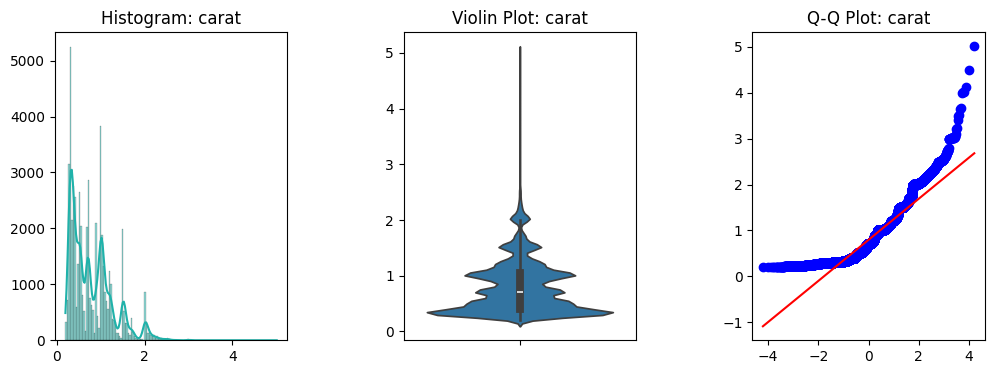

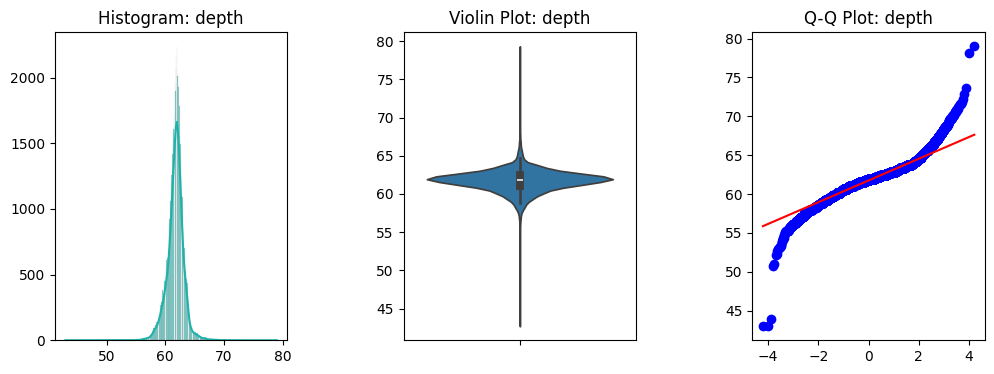

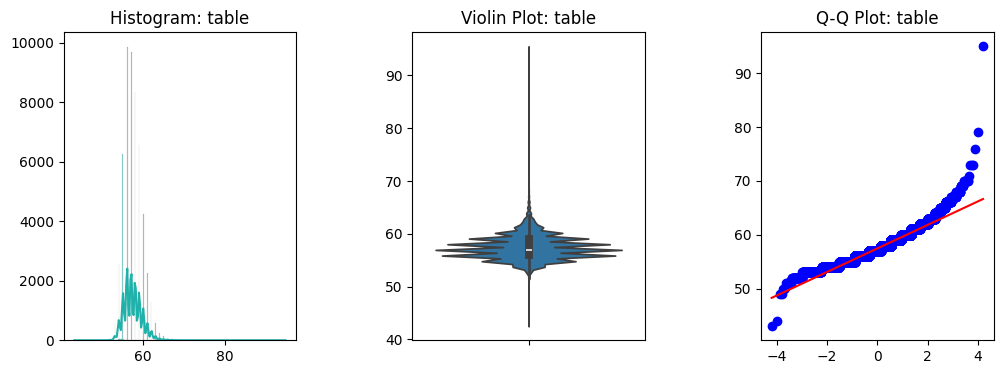

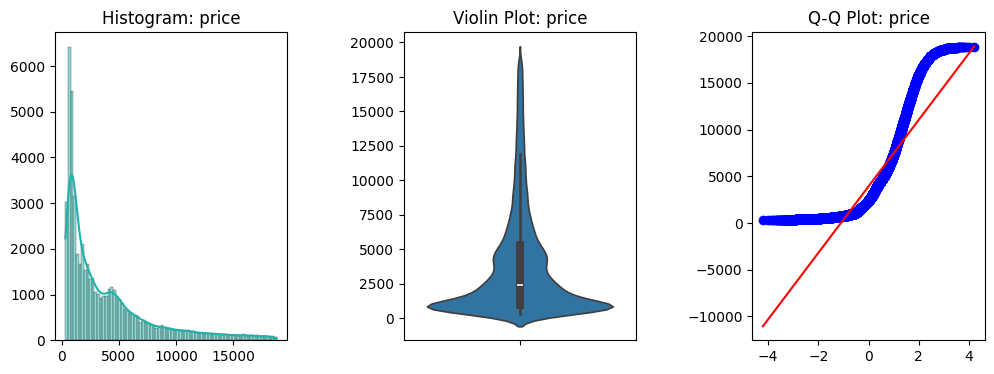

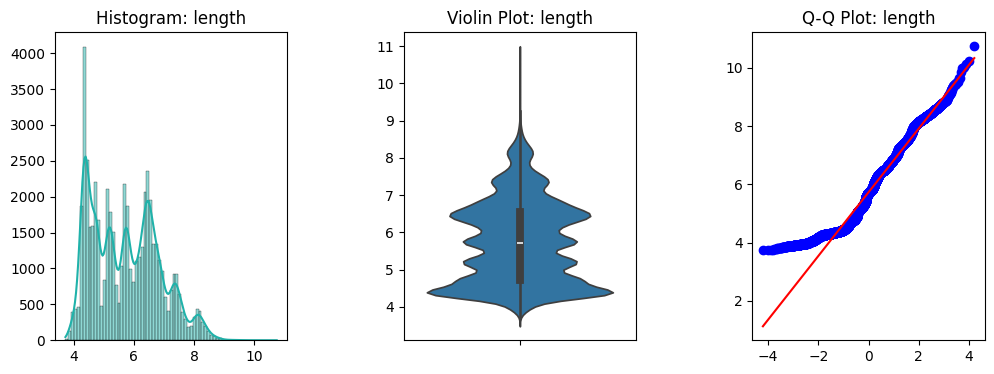

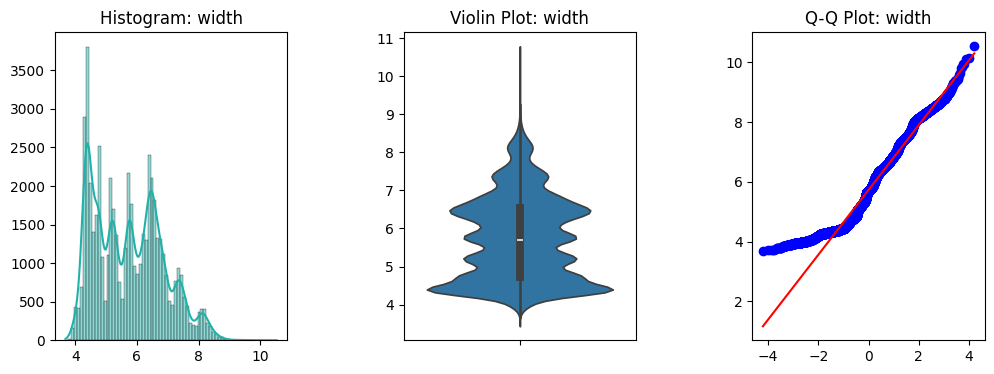

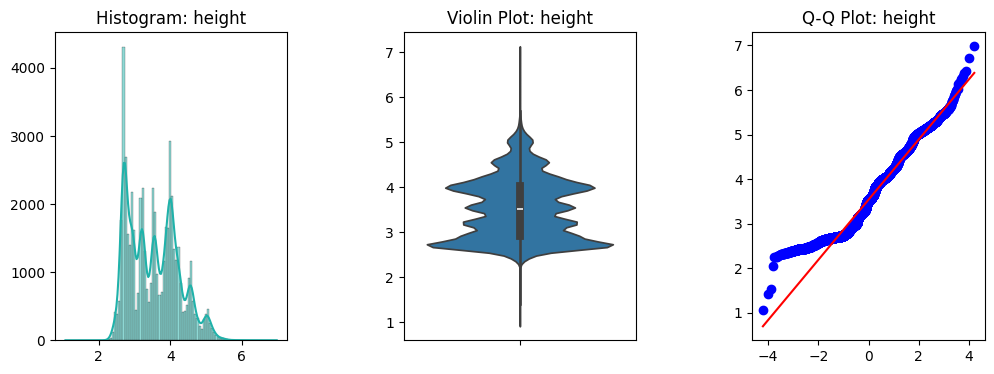

In [23]:
def plot_numerical_features(dframe, num_feats):
  for feature in num_feats:
          # Create a figure and 3 subplots (1 row, 3 columns)
          fig, axes = plt.subplots(1, 3, figsize=(12, 4))
          plt.subplots_adjust(wspace=0.5)

          # Plot 1: Histogram with kde
          sns.histplot(data=dframe, x=feature, kde=True, ax=axes[0], color='lightseagreen')
          axes[0].set_title(f'Histogram: {feature}')
          axes[0].set_xlabel('')
          axes[0].set_ylabel('')

          # Plot 2: Violin Plot
          sns.violinplot(data=dframe, y=feature, ax=axes[1])
          axes[1].set_title(f'Violin Plot: {feature}')
          axes[1].set_xlabel('')
          axes[1].set_ylabel('')

          # Plot 3: Q-Q Plot
          stats.probplot(dframe[feature], plot=axes[2])
          axes[2].set_title(f'Q-Q Plot: {feature}')
          axes[2].set_xlabel('')
          axes[2].set_ylabel('')
          # Display the plots
          plt.show()
          #describe_variation(dframe, feature)

plot_numerical_features(df, numerical_features)

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* Several numerical variables, particularly `price`and `carat`, exhibit strong right-skewness, indicating that their distributions contain a concentration of lower values with a relatively long upper tail. This departure from symmetry is also reflected in the Q-Q plots, where the observations deviate from the theoretical normal line, particularly in the tails.

* The Q-Q plots show that several numerical variables deviate substantially from the the theoretical normal distribution, particularly in the tails. This is consistent with the skewness and kurtosis results and confirms that normality is not a good description of several variables in the dataset. These distributional characteristics will be considered when selecting transformations and modelling approaches.
  * The whole price distribution departs from normality, exhibiting a pronounced S-shaped pattern.
  * Majority of the widths are around roughly 3 - 10mm , we observe 2 very extreme deviations at 32 and 59mm.

* The strong skewness of the `price` target variable indicates that most observations are concentrated at the lower price values, with relatively few high-priced diamonds forming a long upper tail.A logarithmic transformation of the target may be considered to reduce the influence of the long right tail and potentially improve the model's ability to capture relative price differences. The effect of such a transformation will be evaluated during model development.

* The presence of long-tailed distributions highlights the importance of examining potential outliers seperately. Extreme observations may represent legitimate large or expensive diamonds rather than data errors, so they should not be removed solely because they appear in the tails.

### <b>5.1.2 Outlier Analysis</b>

In [24]:
# For each numerical feature determine the percentage of outliers out of all data points
for feature in numerical_features:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df[(df[feature] < lower_bound) | (df[feature] > upper_bound)]
    percentage_outliers = (len(outliers) / len(df)) * 100
    print(f"Percentage of outliers in {feature}: {percentage_outliers:.2f}%")

Percentage of outliers in carat: 3.47%
Percentage of outliers in depth: 4.69%
Percentage of outliers in table: 1.12%
Percentage of outliers in price: 6.54%
Percentage of outliers in length: 0.04%
Percentage of outliers in width: 0.04%
Percentage of outliers in height: 0.05%


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* `price` (6.54%) and `depth` (4.69%) have the highest proportions of IQR-defined outliers among the numerical variables. These observations represent values that fall beyond the 1.5 * IQR thresholds and are therefore identified as potential outliers.
* `carat` has 3.47% of observations outside the IQR-based thesholds. Given the strong right-skewness of carat weight, these observations are likely concentrated toward the upper end of the distribution.


### <b>5.1.3 Categorical Features Distributions</b>

In [25]:
# Create a list with categorical features
categorical_features =[col for col in df.columns if col not in numerical_features]
print(categorical_features)

['cut', 'color', 'clarity']


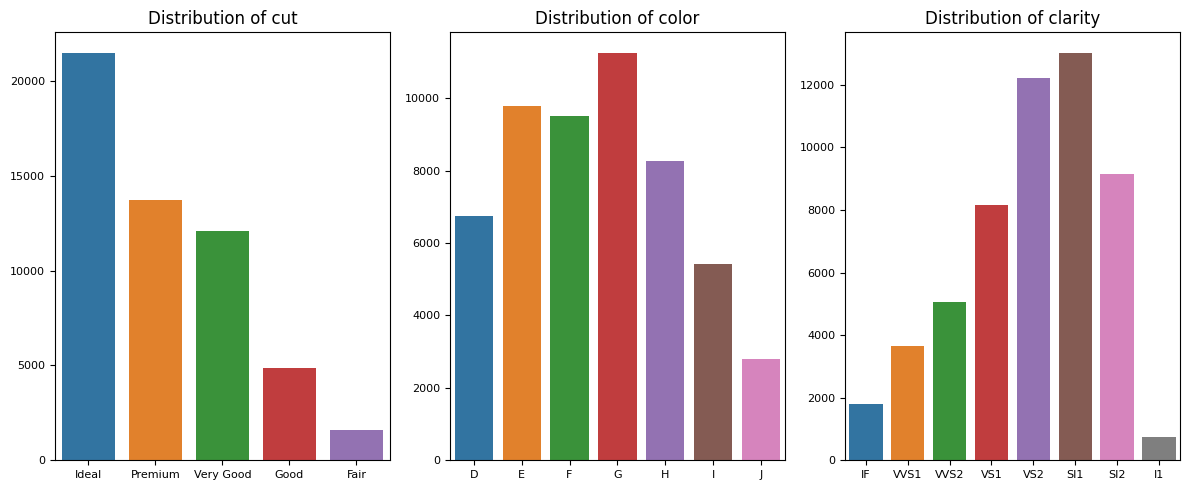

In [26]:
# Set number of plots per row
plts_per_row = 3

# Calculate required number of rows for subplots
nr_features = len(categorical_features)
rows = (nr_features // plts_per_row) + (nr_features % plts_per_row > 0)

# Create subplot grid with appropriate size
fig, axes = plt.subplots(rows, plts_per_row, figsize=(12, 5 * rows))

# Flatten axes array for easy indexing
axes = axes.flatten()

# Loop through each categorical feature to plot its distribution
for i, feature in enumerate(categorical_features):
  feature_counts = df[feature].value_counts().reset_index()
  feature_counts.columns = [feature, 'count']

  # Create barplot for the feature
  sns.barplot(x=feature, y='count', data=feature_counts, hue=feature_counts[feature], ax=axes[i])
  axes[i].set_title(f'Distribution of {feature}')
  axes[i].set_xlabel('')
  axes[i].set_ylabel('')

  # Adjust tick label font sizes
  axes[i].tick_params(axis='x', labelsize=8)
  axes[i].tick_params(axis='y', labelsize=8)

# Remove any unused subplot axes
for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* <b>Cut</b>: The distribution is concentrated in the higher-rated categories, particularly `Ideal` and `Premium`, while `Good` and `Fair` contain fewer observations. This indicates an uneven distribution of cut categories within the dataset.
* <b>Color</b>: The distribution is concentrated in the middle to higher color grades, with `G`, `E` and `F` representing sunstantiall portions of the dataset, while `I` and `J`are less frequent. This indicates that the dataset contains fewer observations at  the lower end of the color grade scale.
* <b>Clarity</b>: `SI1` and `VS2` are the most common clarity grades in the dataset, while the highest clarity grades such as `IF` and `VVS1` occur less frequently. The distribution threrfore contains substantially more observations in the mid-range clarity categories than at the highest clarity levels.






### <b>5.1.4 Multiple-factor ANOVA: Categorical Feature Influence on `price`</b>



We perform a <b>one-way factorial ANOVA</b> to determine whether the categorical variables `cut`, `color`and `clarity` significantly explain variation in diamond `price`. Then we calculte <b>partial eta-squared</b>, an effect size measure that shows how much variance in `price` each feature explains after accounting for the other variables.

In [27]:
# Create a copy of the relevant columns to avoid SettingWithCopyWarning
df_anova = df[categorical_features + ['price']].copy()

# Convert categorical variables to categorical dtype using .loc
df_anova.loc[:, 'cut'] = df_anova['cut'].astype('category')
df_anova.loc[:, 'color'] = df_anova['color'].astype('category')
df_anova.loc[:, 'clarity'] = df_anova['clarity'].astype('category')

# Perform ANOVA
model = smf.ols('price ~ cut + color + clarity', data=df_anova).fit()
anova_results = sm.stats.anova_lm(model, typ=2)

# Residual sum of squares
ss_error = anova_results.loc['Residual', 'sum_sq']

# Create effect-size table excl.residual
effect_sizes = anova_results.drop('Residual').copy()

# Calculate the denominator for partial eta-squared
effect_error_total_ss = effect_sizes['sum_sq'] + ss_error

# Partial eta squared
effect_sizes['partial_eta_sq'] = effect_sizes['sum_sq'] / effect_error_total_ss

effect_sizes

,sum_sq,df,F,PR(>F),partial_eta_sq
cut,5.477267e+09,4.0,92.177102,2.981079e-78,0.006812
color,2.623930e+10,6.0,294.388070,0.000000e+00,0.031814
clarity,1.979208e+10,7.0,190.332271,5.355638e-280,0.024186


In [28]:
for feat in categorical_features:
  p_val = effect_sizes.loc[feat, 'PR(>F)']
  if p_val < 0.05:
    print(f"The {feat} feature has a significant impact on diamond price.")
  else:
    print(f"The {feat} feature does not have a significant impact on diamond price.")

The cut feature has a significant impact on diamond price.
The color feature has a significant impact on diamond price.
The clarity feature has a significant impact on diamond price.


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>


* The Type II ANOVA indicates that `cut`, `color`, and `clarity` are all statistically significant predictors of price (p < 0.05 for all factors). This means that the mean diamond price differs significantly across the levels of each categorical feature, even after accounting for the effects of the other factors.

* Among the three categorical variables, `color` shows the largest variation in average price across its groups. This suggests that diamond colour grade has the strongest association with price differences in the dataset, relative to cut and clarity.

##  <font color=#0000CD>5.2 Bivariate Analysis</font>

### <b>5.2.1 Price Distribution by Categorical Features</b>

<i>How do cut, color and clarity relate to price?</i>

In [29]:
def histplot_categorical_feat(feature):
    plt.figure(figsize=(6, 4))
    sns.histplot(data=df, x='price', hue=feature, kde=True, palette='coolwarm')
    plt.title(f'Distribution of Prices by {feature}')
    plt.xlabel('Price')
    plt.ylabel('Count')
    plt.show()


def boxplot_categorical_feat(feature, order):
    plt.figure(figsize=(6, 4))
    sns.boxplot(x='price', y=feature, data=df, showmeans=True, order=order,palette='coolwarm', hue=feature,
                meanprops={"marker":"o","markerfacecolor":"red", "markeredgecolor":"black","markersize":"5"})
    plt.title(f'Boxplot of Diamond prices by {feature}')
    plt.ylabel("")
    plt.show()

#### <font color=#008B8B>5.2.1.1 Distribution of Price by Cut</font>

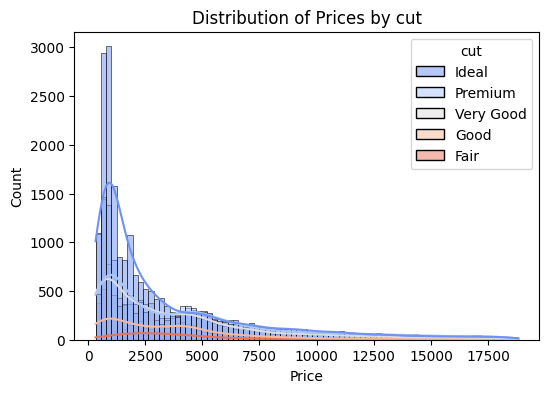

In [30]:
histplot_categorical_feat('cut')

In [31]:
print("Descriptive statistics: price for each cut")
df.groupby('cut', observed=False)['price'].describe()

Descriptive statistics: price for each cut


,count,mean,std,min,25%,50%,75%,max
cut,,,,,,,,
Ideal,21484.0,3462.212716,3810.696372,326.0,878.00,1813.0,4685.25,18806.0
Premium,13736.0,4578.358256,4342.404156,326.0,1046.00,3177.5,6290.00,18823.0
Very Good,12067.0,3981.086848,3935.082561,336.0,912.00,2647.0,5371.50,18818.0
Good,4888.0,3916.279051,3665.923858,327.0,1143.25,3038.0,5015.75,18707.0
Fair,1597.0,4340.677520,3540.858952,337.0,2049.00,3282.0,5185.00,18574.0


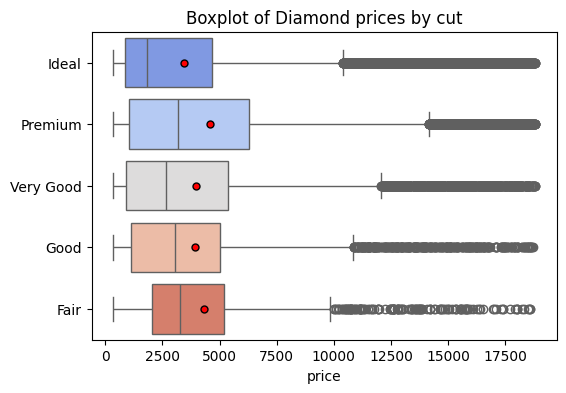

In [32]:
boxplot_categorical_feat('cut', cut_order)

<font color=red> The red dots represent the mean price for each cut grade.</font>

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* `Ideal` and `Premium` contain the largest number of diamonds, with prices concentrated toward the lower end and long upper tails across all cut grades.
Price distributions are heavily right-skewed across all cut grades, with substantial overlap between categories.
* The boxplot shows that `Ideal` diamonds can have lower absolute prices than `Premium` or even `Fair` diamonds, illustrating that cut quality alone does not determine absolute price.
* This pattern is consistent with the strong influence of `carat weight` on absolute `price`: larger diamonds with lower cut grades can cost more than smaller diamonds with higher cut grades.

<b>Cut quality matters, but it does not determine absolute price independently of diamond size.</b>

#### <font color=#008B8B>6.2.1.2 Distribution of Price by Color</font>





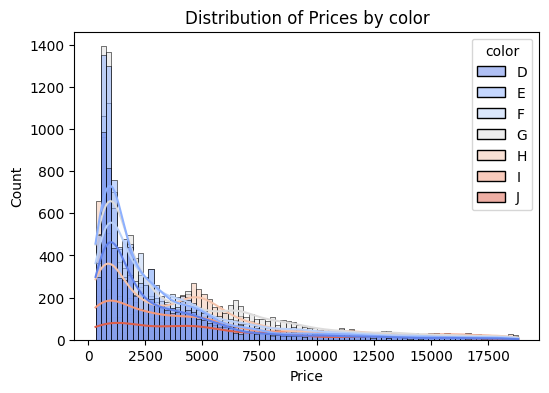

In [33]:
histplot_categorical_feat('color')

In [34]:
print("Descriptive statistics: price for each color")
df.groupby('color', observed=False)['price'].describe()

Descriptive statistics: price for each color


,count,mean,std,min,25%,50%,75%,max
color,,,,,,,,
D,6754.0,3172.588540,3356.071616,357.0,911.00,1842.0,4214.0,18693.0
E,9774.0,3079.824330,3346.977031,326.0,882.00,1740.0,4004.0,18731.0
F,9517.0,3726.776820,3787.040164,342.0,982.00,2345.0,4876.0,18791.0
G,11254.0,3999.088502,4049.429795,354.0,931.25,2242.0,6048.0,18818.0
H,8265.0,4476.167574,4203.264006,337.0,984.00,3447.0,5958.0,18803.0
I,5406.0,5079.843137,4715.630590,334.0,1111.50,3720.0,7162.0,18823.0
J,2802.0,5326.415418,4433.735840,335.0,1864.00,4234.5,7695.0,18710.0


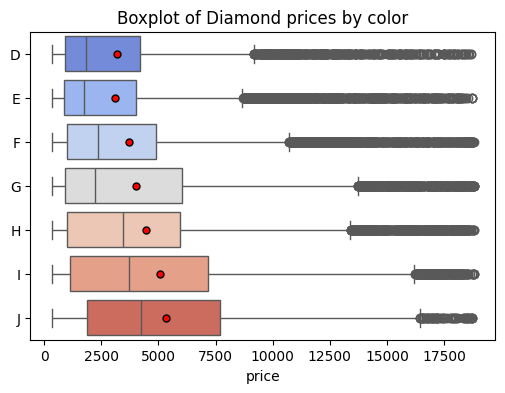

In [35]:
boxplot_categorical_feat('color', color_order)

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* Prices are strongly right-skewed across all `color` grades, with most diamonds concentrated at lower price levels and a smaller number of high-priced diamonds forming long upper tails.
* The descriptive statistics and boxplots show substantial overlap in `price` distributions across color grades, indicating that color alone does not separate diamonds into distinct price ranges.
* The boxplots also show differences in the central tendency and spread of prices between color groups, but the substantial overlap suggests that other factors, particularly `carat weight`, also play an important role in determining absolute price.

#### <font color=#008B8B>5.2.1.3  Distribution of Price by Clarity</font>


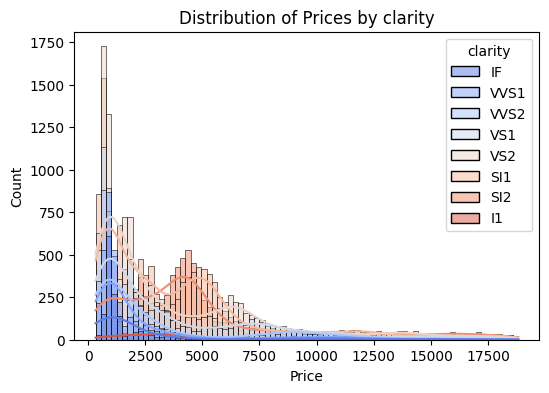

In [36]:
histplot_categorical_feat('clarity')

In [37]:
print("Descriptive statistics: price for each clarity level")
df.groupby('clarity', observed=False)['price'].describe().reset_index()

Descriptive statistics: price for each clarity level


,clarity,count,mean,std,min,25%,50%,75%,max
0,IF,1784.0,2870.569507,3925.564866,369.0,895.00,1080.0,2391.50,18806.0
1,VVS1,3646.0,2522.993692,3330.985401,336.0,816.00,1094.0,2380.75,18777.0
2,VVS2,5056.0,3286.532437,3823.399309,336.0,794.75,1316.0,3646.75,18768.0
3,VS1,8153.0,3841.746106,4011.803963,327.0,876.00,2010.0,6025.00,18795.0
4,VS2,12225.0,3925.614806,4039.558033,334.0,900.00,2057.0,6027.00,18823.0
5,SI1,13030.0,3994.271834,3796.591029,326.0,1090.00,2822.0,5249.00,18818.0
6,SI2,9141.0,5053.746308,4251.018206,326.0,2264.00,4071.0,5758.00,18804.0
7,I1,737.0,3927.303935,2813.362280,345.0,2068.00,3348.0,5170.00,18531.0


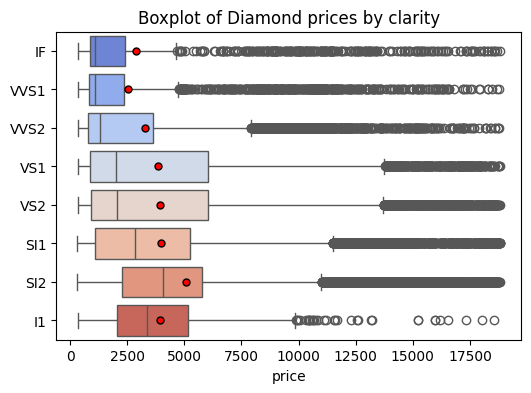

In [38]:
boxplot_categorical_feat('clarity', clarity_order)

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* Prices are strongly right-skewed across all clarity grades, with most diamonds concentrated at lower price levels and a smaller number of high-priced diamonds extending into the upper tail.
* `SI1` and `VS2` contain the largest number of observations, while the higher clarity grades such as `IF` and `VVS1` have  fewer observations.
* The descriptive statistics and boxplots show substantial overlap in price distributions across clarity grades, indicating that clarity alone does not define distinct price ranges.
* The boxplots show differences in the median prices and spread between clarity groups, but the considerable overlap indicates that other characteristics particularly `carat` weight, also contribute strongly to absolute price.


### <b>5.2.2 Impact of Carat on Price</b>

<i>How does size relate to price and why do the categorical price distributions overlap?</i>

The preceding analysis showed extensive overlap in `price` across `cut`, `color` and `clarity`groups, with some higher quality diamonds having lower prices than diamonds with lower quality grades. This suggests that another characteristic, particularly diamond size, may have a stronger influence on `price`. To examine this relationship directly , we next analyze how `average price` changes with `carat`.

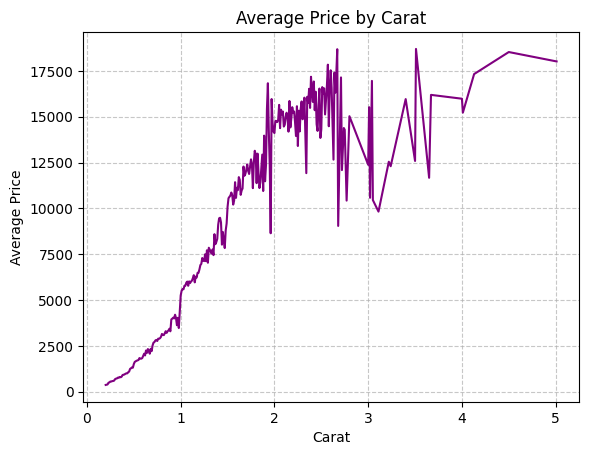

In [39]:
# Calculate average price for each carat value
carat_price = df.groupby('carat')['price'].mean().reset_index()

# Plot the average price against carat using a line plot
sns.lineplot(data=carat_price, x='carat', y='price', color='purple')
plt.title('Average Price by Carat')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlabel('Carat')
plt.ylabel('Average Price')
plt.show()

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b>

* There is a clear, strong positive relationship between carat weight and  average price. As `carat` increases, `average diamond price` rises sharply.
* This provides an important explanation for the overlapping price distributions we observed across `cut`, `color` and `clarity`; diamonds with higher quality grades can have lower absolute prices when they are smaller, while larger diamonds with lower quality grades can command higher prices.
* These results indicate that diamond size, particularly `carat`weight , is a major factor in absolute price and warrants closer examination in the following multivariate analysis.

### <b>5.2.3 Categorical Feature Dependencies</b>

<i>Are cut , color and clarity related to each other?</i>

The previous analysis examined how cut, color and clarity relate to diamond price individually. Before examining combinations of these features, it is also useful to determine whether the categorical preditors themselves are statistically associated.

<b>Chi-square tests of independence</b> are used to determine whether pairs of categorical features are independent or associated. Because statistical significance alone does not indicate the strength of an association, <font color = #4169E1>Cramér's V</font> is then used to <font color = #4169E1>quantify the strength of each relationship</font>.

#### <font color=#008B8B>5.2.3.1 Chi-square : Is their a relationship?

In [40]:
#categorical_features

In [41]:
# Loop through all unique pairs of categorical features
for var1, var2 in combinations(categorical_features, 2):

    # Create a contingency table for the two variables
    contingency_table = pd.crosstab(df[var1], df[var2])

    # Perform the Chi-square test of independence
    chi2_stat, p_val, _, _ = chi2_contingency(contingency_table)
    print(f"Chi-square test between {var1} and {var2}: Chi2 Stat = {chi2_stat:.2f}, P-value = {p_val:.4f}")

    # Interpret the result based on significance level (0.05)
    if p_val < 0.05:
        print(f"{var1.capitalize()} and {var2} are associated.\n")
    else:
        print(f"{var1.capitalize()} and {var2} are not associated.\n")


Chi-square test between cut and color: Chi2 Stat = 306.31, P-value = 0.0000
Cut and color are associated.

Chi-square test between cut and clarity: Chi2 Stat = 4372.70, P-value = 0.0000
Cut and clarity are associated.

Chi-square test between color and clarity: Chi2 Stat = 2040.47, P-value = 0.0000
Color and clarity are associated.



#### <font color=#008B8B>5.2.3.2 Cramér's V : How strong is that relationship?





In [42]:
def cramers_v(x, y):
    """Calculate Cramér's V statistic for categorical-categorical association."""

    # Create a contingency table between the two categorical variables
    confusion_matrix = pd.crosstab(x, y)

    # Perform Chi-square test on the contingency table
    chi2, _, _, _ = chi2_contingency(confusion_matrix)

    # Total number of observations
    n = confusion_matrix.sum().sum()

    # Compute raw phi-squared value
    phi2 = chi2 / n

    # Get number of rows and columns in the contingency table
    r, k = confusion_matrix.shape

    # Apply bias correction to phi-squared
    phi2_corr = max(0, phi2 - ((k - 1)*(r - 1)) / (n - 1))

    # Corrected row and column counts
    r_corr = r - ((r - 1)**2) / (n - 1)
    k_corr = k - ((k - 1)**2) / (n - 1)

    # Calculate Cramér's V with bias correction
    v = np.sqrt(phi2_corr / min((k_corr - 1), (r_corr - 1)))

    return v

def interpret_strength(v):
    """Return strength label based on Cramér's V value."""

    # Categorize the strength of association based on thresholds
    if v < 0.10:
        return "Negligible"
    elif v < 0.30:
        return "Weak"
    elif v < 0.50:
        return "Moderate"
    else:
        return "Strong"

# Define the list of categorical features to analyze
categorical_features = ['cut', 'color', 'clarity']

# Loop through all unique pairs of categorical features
for var1, var2 in combinations(categorical_features, 2):

    # Compute Cramér's V for the pair
    v = cramers_v(df[var1], df[var2])

    # Interpret the strength of the association
    strength = interpret_strength(v)

    print(f"Cramér’s V between {var1} and {var2}: {v:.4f} → {strength} association")


Cramér’s V between cut and color: 0.0362 → Negligible association
Cramér’s V between cut and clarity: 0.1421 → Weak association
Cramér’s V between color and clarity: 0.0787 → Negligible association


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* <b>The Chi-squared tests show statistically significant association between all three pairs of categorical features</b> : `cut`, `color` and `clarity` (p < 0.05 for all pairs). This means these features are not statistically independent in this dataset.

<font color=darkslategray>However, statistical significance does not indicate strength of these relationships, Given the large dataset size, even relatively weak associations can produce very small p-values. Cramér's V is therefore used to quantify the strength of each association.</font>

* Cramér's V shows that the statistically significant associations identified by  Chi-square tests are relatively weak in strength. The association between cut and clarity is weak (V = 0.1423), while associations between cut and color (V = 0.0364) and color and clarity (V = 0.0788) are negligible.

<font color=darkslategray>Therefore, although the categorical features are not completely independent, <b>the results do no suggest strong redundancy between feature pairs</b>. All three categorical features are therefore retained for modelling.</font>



### <b>5.2.4 Categorical Feature Interactions</b>






<i>How do combinations of the categorical features relate to each other?</i>

The previous analyses showed that `carat` weight has a strong relationship with `price`, while price distributions across `cut`, `color` and `clarity` show extensive overlap. To examine the categorical price patterns while accounting for differences in diamond size, we calculate `price_per_carat`.

In [43]:
df['price_per_carat'] = df['price'] / df['carat']

#### <font color=#008B8B>5.2.4.1 Price-per-Carat  vs Cut and Color




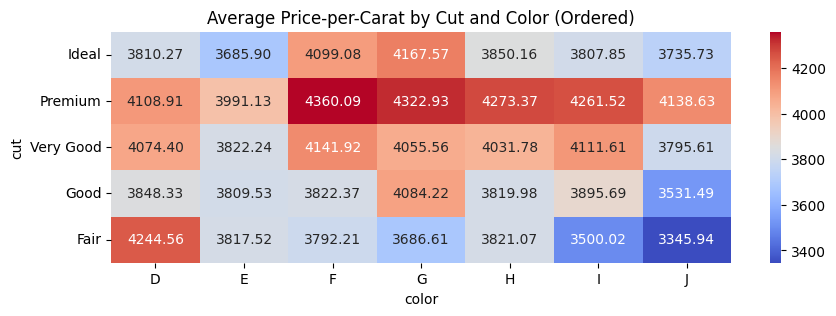

In [44]:
# Create a pivot table showing average price-per-carat by cut and color
ppc_pivot_cut_col = pd.pivot_table(
    df,
    values='price_per_carat',
    index='cut',
    columns='color',
    aggfunc='mean',
    observed=False
)

plt.figure(figsize=(10, 3))
sns.heatmap(ppc_pivot_cut_col, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Average Price-per-Carat by Cut and Color (Ordered)")
plt.show()

#### <font color=#008B8B>5.2.4.2 Price-per-Carat  vs Cut and Clarity

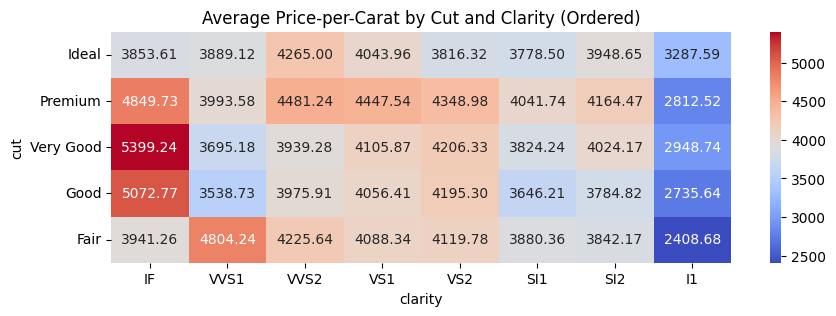

In [45]:
ppc_pivot_cut_clar = pd.pivot_table(df, values='price_per_carat', index='cut', columns='clarity', aggfunc='mean', observed=False)
plt.figure(figsize=(10, 3))
sns.heatmap(ppc_pivot_cut_clar, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Average Price-per-Carat by Cut and Clarity (Ordered)")
plt.show()

#### <font color=#008B8B>5.2.4.3 Price-per-Carat  vs Color and Clarity









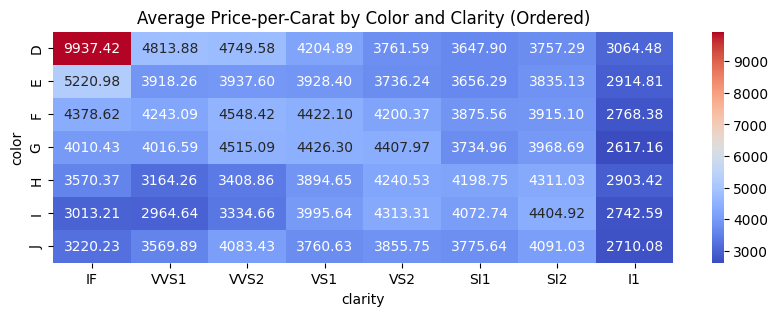

In [46]:
ppc_pivot_col_clar = pd.pivot_table(df, values='price_per_carat', index='color', columns='clarity', aggfunc='mean', observed=False)
plt.figure(figsize=(10, 3))
sns.heatmap(ppc_pivot_col_clar, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Average Price-per-Carat by Color and Clarity (Ordered)")
plt.show()

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* The heatmaps shows that different combinations of `cut`, `color`, and `clarity` have different average prices per carat.</font>.

* The patterns also show that <font color=darkblue>the effect of one categorical feature cannot be intepreted independently of the others</font>. For example, the relative `price_per_carat` associated with a `cut` grade can differ across color or `clarity` grades.

* These heatmaps provide a descriptive view of the combined categorical pattens, while also reinforcing that <font color=darkblue><b>price differences can not be explained by a single quality attribute in isolation</b>.</font>


## <font color=#0000CD>5.3 Multivariate Analysis

The previous analyses examined individual relationships between diamond characteristics and price, as well as patterns across categorical features. Multivariate analysis now considers several numerical features together to understand how they relate to price and to each other. This helps <b>identify strong linear relationships with price</b> and detect <b>correlation between predictors</b> that may affect model interpretation and feature selection.

### <b>5.3.1 Correlation and Relationship Analysis</b>

Correlation analysis provides an initial view of the linear relationships among the numerical features and the target variable `price`. The correlation matrix is used to identify which numerical features are most strongly associated with price and which predictors are highly correlated with one another.

#### <font color=#008B8B>5.3.1.1 Correlation Matrix

<i>How do the numerical predictors relate to price?</i>

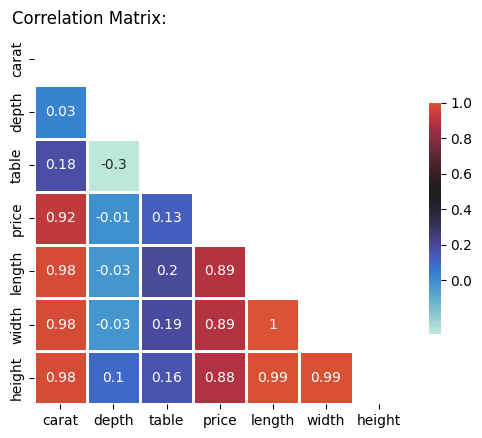

In [47]:
corr_matrix = df[numerical_features].corr().round(2)
# Generate a mask to the upper triangle of the matrix
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(6, 6))
ax = sns.heatmap(corr_matrix, mask=mask,  vmax=1, center=0.5,
                 square=True, linewidths=0.8,
                 cbar_kws={"shrink": .5, 'ticks':[0, 0.2, 0.4, 0.6, 0.8, 1]}, annot=True)
plt.title("Correlation Matrix:", x=0.15)
plt.show()

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* Carat is the dominant driver of price, explaining most of the variation.
* Depth is not predictive of price or carat.
* Length, width, and height are highly collinear, meaning they measure similar underlying size.
* If you plan to build a regression model, multicollinearity among x, y, z and carat must be handled (e.g., via PCA or dropping redundant variables).

Drop `depth` because it shows almost no linear relationship with `price` in the correlation analysis. Removing it simplifies the numerical feature set before the pair-plot analysis.

In [48]:
df_without_depth = df.drop(columns=['depth'])
numerical_features.remove('depth')

#### <font color=#008B8B>5.3.1.2 Pair Plot Visualization</font>

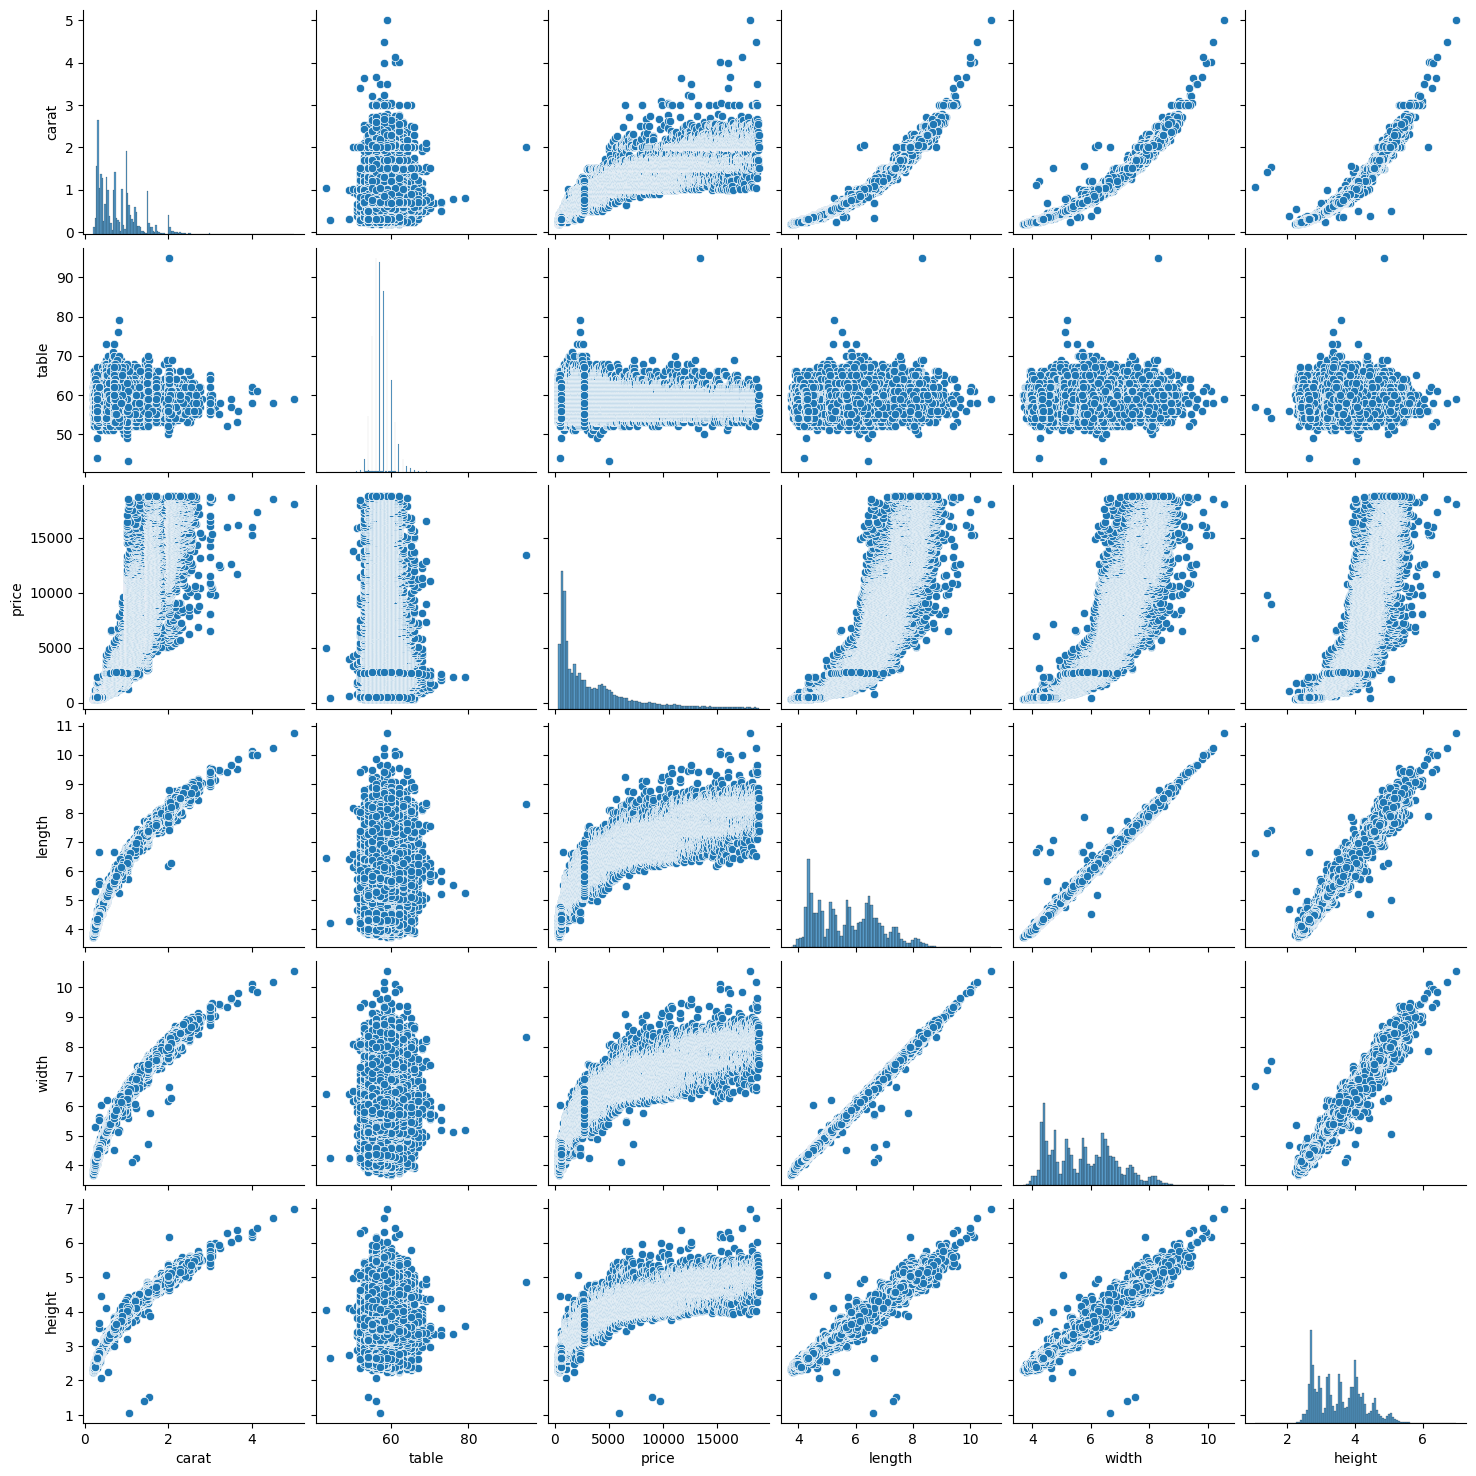

In [49]:
# Pair plot of selected continuous variables
sns.pairplot(df_without_depth[numerical_features])
plt.show()

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* `carat` shows the <font color=4169E1>strongest visible positive relationship</font> with `price` among the numerical features where higher carat diamonds are generally associated with higher prices.

* Strong positive relationships are also visible between `price` and physical dimensions `length`, `width` and `height` consistent with the earlier correlation analysis.

* The size-related variables ( `carat`, `length`, `width` and `height`) show strong relationships with one another, confirming the <b>multicollinearity</b> identified in the correlation matrix.

* `table` shows comparatively weak relationships with `price` and with the other numerical predictors.

* The relationships between `price` and size-related variables are not perfectly linear, suggesting that `price` does not increase at a constant rate as diamond size increases.

<font color=darkslategray><b>Overall, the pair plots reinforce the strong association between size and price and also once again highlights extensive overlap among the size related predictors</b>.

#<u><font color=#000080>6. Data Preprocessing</font></u>





The exploratory and multivariate analysis identified several characteristics that need to be addressed before model training, including <b>skewed numerical distributions</b>, <b>categorical variables</b> and <b>strong correlations among dimensional features</b>.

The data is therefore prepared for modelling through a structured preprocessing pipeline. This includes seperating the target from the predictors, creating training, validation and test sets. Then transforming skewed variables, encoding categorical features and standardizing the resulting numerical feature set.

## <font color=#0000CD>6.1 Train, Validation and Test Split</font>



In [50]:
# Define feature matrix X and target y
'''
We remove 'price' and 'price_per_carat' from the feature set.
'price' is the target variable and 'price_per_carat' is derived
from 'price', so keeping it would leak target information into the model.
'''
X = df_without_depth.drop(columns=['price', 'price_per_carat'])

# Target variable : original diamond price
y = df_without_depth['price']

In [51]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Further split training dataset into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)


```
                   FULL DATASET
                         │
              ┌──────────┼──────────┐
              ▼          ▼          ▼
          TRAIN 64%   VALIDATION 16%  TEST 20%
              │          │              │
              ▼          ▼              │
          Train models  Compare         │
                        models          │
                         │              │
                         ▼              │
                  Tune models           │
                         │              │
                         └──────┐       │
                                ▼       │
                         Final model    │
                                │       │
                                └──────►│
                                        ▼
                              FINAL TEST EVALUATION
```
Keeping these datasets seperate helps to reduce the risk of data leakage that ensures that final model performance is evaluated on data that was not used during training or tuning.

In [52]:
# Identify numerical features
num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [53]:
# Create copies for transformed versions
'''
We can apply scaling/encoding without modifying the
original train/validation/test split.
'''
X_train_t = X_train.copy()
X_val_t = X_val.copy()
X_test_t = X_test.copy()

# Flatten y arrays for sklearn compatibility
y_train_t = y_train.values.ravel().copy()
y_val_t = y_val.values.ravel().copy()
y_test_t = y_test.values.ravel().copy()

## <font color=#0000CD>6.2 Log Transformations to Skewed Features and Target</b>












The EDA identified strong right-skewness in several numerical features, particularly `carat` and `price`. To reduce the effect of this skewness, a <b>log1p transformation</b> is applied to the numerical features and the target variable, `price`.

$$log1p(x) = log(1 + x) $$

<font color=darkslategray>log1p is used to reduce the strong right-skewness in the numerical features and `price`, while also handling values close to zero mpre effectively than the standard log transformation logp</font>.

The same transformation is applied consistently to the training, validation and test sets, while the transformation itself is defined without fitting parameters from the validation and test sets.

Price distribution before the log1p transformation


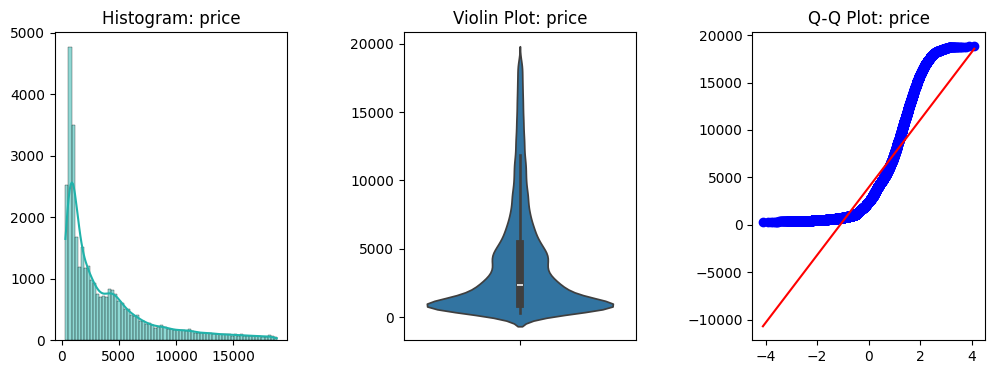



Price distribution after the log1p transformation


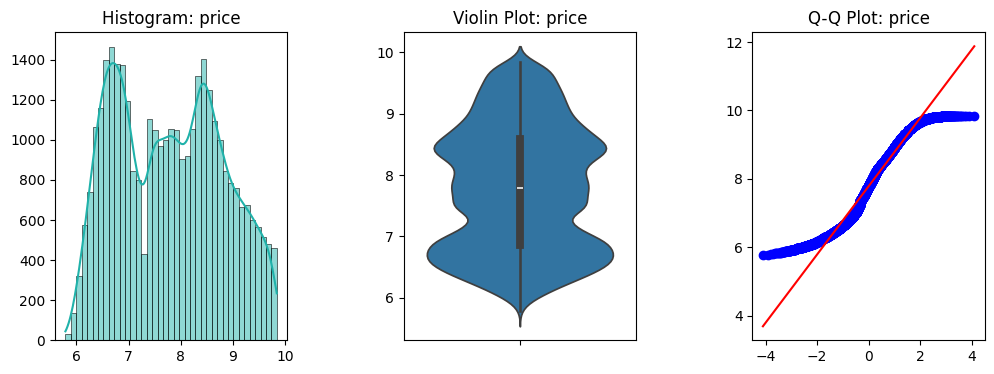

In [54]:
# Log-transform right-skewed numerical features

# Apply log1p transformation to numerical features in train, val and test sets
X_train_t[num_features] = np.log1p(X_train_t[num_features])
X_val_t[num_features] = np.log1p(X_val_t[num_features])
X_test_t[num_features] = np.log1p(X_test_t[num_features])


#Apply log1p transformation to the target variable (price)
y_train_t = np.log1p(y_train_t)
y_val_t = np.log1p(y_val_t)
y_test_t = np.log1p(y_test_t)

#Price distribution before the transform
y_train_plt = pd.DataFrame(y_train, columns=['price'])
print("Price distribution before the log1p transformation")
plot_numerical_features(y_train_plt, ['price'])

# Price distribution after the log1p transformation
y_train_t_plt = pd.DataFrame(y_train_t, columns=['price'])
print("\n\nPrice distribution after the log1p transformation")
plot_numerical_features(y_train_t_plt, ['price'])

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* The <b>logp1 transformation</b> <font color=blue>substantially reduces the strong right-skewness</font> observed in the original `price` distribution by compressing the upper tail.

* The transformed distribution is <font color=blue>more concentrated and less dominated by extreme high-price values</font> which is also reflected in the violinplot.

* The Q-Q plot still shows noticeable deviation from the reference line, indicating that <font color=blue>the log1p transformation does not make `price` normally distributed</font>.

* The transformed histogram retains some non-uniform structure, so the transformation should be viewed as reducing skewness rather than achieving normality.

## <font color=#0000CD>6.3 Target Encoding of Categorical Features</b>

Target encoding was selected to convert the categorical features `cut`, `color` and `clarity` into numerical representations based on their relationship with diamond `price`. This approach was preferred over one-hot encoding to limit the expansion of the feature set.

The encoder is fitted using the training data and its corresponding target values, then applied to the validation and test features without using their target values during fitting.

One limitation of this approach is that the training observations contribute to the category statistics used to encode the training data, including their own target values. This can make training performance optimistic, particularly for categories with few observations, and should be considered when interpreting the model's results.

Target encoding converts each categorical value into a numerical representation based on its relationship with target variable. In this project, `cut`, `color` and `clarity` are encoded using the log-transformed `price`, with the encoder fitted only on the training data to avoid target leakage.

In [55]:
quality_cols = ['cut', 'color', 'clarity']

enc = OrdinalEncoder(
     categories=[cut_order[::-1], color_order[::-1], clarity_order[::-1]] , # worst -> best
     handle_unknown = 'error'  # Fail loud when unknown grade is observed
)

enc.set_output(transform='pandas')  # Keep column names in a dataframe format

X_train_encoded = enc.fit_transform(X_train_t[quality_cols])
print(X_train_encoded.describe())
X_val_encoded = enc.transform(X_val_t[quality_cols])
X_test_encoded = enc.transform(X_test_t[quality_cols])

# Sanity Checks : row counts must match before combining
assert len(X_train_encoded) == len(X_train_t)
assert len(X_val_encoded) == len(X_val_t)
assert len(X_test_encoded) == len(X_test_t)

# Combine encoded categorical features with numerical features
# Drop original categorical cols and replace with encoded versions
X_train_all = pd.concat([X_train_encoded, X_train_t.drop(columns=categorical_features)], axis=1)
X_val_all = pd.concat([X_val_encoded, X_val_t.drop(columns=categorical_features)], axis=1)
X_test_all = pd.concat([X_test_encoded, X_test_t.drop(columns=categorical_features)], axis=1)

                cut         color       clarity
count  34413.000000  34413.000000  34413.000000
mean       2.903380      3.403336      3.054456
std        1.115207      1.701529      1.645655
min        0.000000      0.000000      0.000000
25%        2.000000      2.000000      2.000000
50%        3.000000      3.000000      3.000000
75%        4.000000      5.000000      4.000000
max        4.000000      6.000000      7.000000


## <font color=#0000CD>6.4 Feature Standardization





After log transformation and target encoding, the predictor variables are standardized using `StandardScaler`. Standardization puts the features on a comparable scale by centering them around zero and scaling them to unit variance. This is particularly important for scale-sensitive models such as Linear Regression, Ridge, Lasso, Support Vector Regression and K-Nearest Neighbours.



In [56]:
# Standardize numerical features
scaler = StandardScaler()

# Fit on training data and transform
X_train_p_arr = scaler.fit_transform(X_train_all)

# Apply the same transformation to the validation and test data using the fitted scaler
X_val_p_arr = scaler.transform(X_val_all)
X_test_p_arr = scaler.transform(X_test_all)

# Convert the numpy arrays back to DataFrame for easier handling
X_train_p = pd.DataFrame(X_train_p_arr, columns=X_train_all.columns)
X_val_p = pd.DataFrame(X_val_p_arr, columns=X_val_all.columns)
X_test_p = pd.DataFrame(X_test_p_arr, columns=X_test_all.columns)

# Preserve the log-transformed target variables for modeling
y_train_p = y_train_t.copy()
y_val_p = y_val_t.copy()
y_test_p = y_test_t.copy()

The final preprocessing pipeline produces a consistent feature set consisting of:

* Log-transformed numerical features
* Target-encoded categorical features
* Standardised predictor variables
* Log-transformed target variable (`price`)

These transformations prepare the data for model training by <b>reducing skewness</b>, <b>converting categorical features into numerical representations</b>, and <b>putting predictor variables on a comparable scale</b>. The preprocessing steps are fitted using the training data where applicable, with the resulting transformations applied consistently to the validation and test sets, helping to <b>reduce the risk of data leakage</b>.

The resulting datasets are now ready for <font color=#3457D5>model training</font>, <font color=#3457D5>comparison</font>, <font color=#3457D5>hyperparameter tuning</font> and <font color=#3457D5>final evaluation</font>.

#<u><font color=#000080>7. Model Building and Evaluation</font></u>

With the preprocessing pipeline complete, the prepared datasets are used to train and evaluate a range of regression models for diamond price prediction. The models include linear and regularized regression approached as well as tree-based ensemble methods, allowing their performance to be compared across different modelling approaches.

Each model is trained using the training set and evaluated on the validation set using consistent performance metrics. The validation results support model comparison and tuning, while the test set is reserved for final perfomance evaluation.

## <b>7.1 Model Evaluation Framework</b>

Because the target variable `price` is log-transformed during preprocessing, the models are trained to predict <b>log1p(price)</b>. For metrics expressed in the original price units, the predictions and corresponding actual values are converted back to the original price scale using the inverse of the transformation <b>expm1</b>.

<font color=indigo>Model performance is evaluated using several complementary metrics:</font>

- <font color=indigo>**RMSE** (Root Mean Squared Error): Measures prediction error in the original price units while giving greater weight to larger errors.</font>
- <font color=indigo>**MAE** (Mean Absolute Error): Measures the average absolute difference between predicted and actual prices in the original price units.</font>
- <font color=indigo>**MedAE** (Median Absolute Error): Measures the median absolute prediction error (typical) and is less influenced by extreme errors than RMSE:</font>
- <font color=indigo>**R²** (Coefficient of Determination): Measures the proportion of variance explained by the model. In this project R² is calculated on the log-transformed target because the models are trained to predict log1p(price). RMSE, MAE, MedAE are calculated after converting predictions back to the original price scale so that their values remain directly interpretable in price units.</font>
- <font color=indigo>**RMSE as a Percentage of Mean Price**: Expresses RMSE relative to the mean price, providing additional context for the magnitude of the prediction error.</font>

In [57]:
# Initialize model comparison table
'''
This dataframe will store performance metrics for each model.
'''
model_comparison_df = pd.DataFrame(columns=[
    'Model',
    'RMSE(train)',
    'RMSE(val)',
    'RMSE(% Mean Price)',
    'R²(train)',
    'R²(val)',
    'MAE(val)',
    'MedAE(val)'])


In [58]:
def evaluate_model(model_name, model, X_train_m, X_val_m, y_train_m, y_val_m):
    # Predict in log scale
    y_pred_log_train = model.predict(X_train_m)
    y_pred_log_val = model.predict(X_val_m)

    # Convert predictions back to original scale
    y_pred_train_orig = np.expm1(y_pred_log_train)
    y_pred_val_orig = np.expm1(y_pred_log_val)

    # Convert actual target values back to original scale
    y_train_orig = np.expm1(y_train_m)
    y_val_orig = np.expm1(y_val_m)

    # Compute RMSE(original scale)
    rmse_train = np.sqrt(mean_squared_error(y_train_orig, y_pred_train_orig))
    rmse_val = np.sqrt(mean_squared_error(y_val_orig, y_pred_val_orig))

    # Calculate Mean Absolute Error (validation set)
    mae_val = mean_absolute_error(y_val_orig, y_pred_val_orig)

    # Calculate Median Absolute Error (validation set)
    medae_val = median_absolute_error(y_val_orig, y_pred_val_orig)

    # RMSE normalized by mean price
    mean_price = y_val_orig.mean().item()
    rmse_mean_pct = (rmse_val / mean_price) * 100

    # R² (log scale — correct for transformed targets)
    r2_train_log = r2_score(y_train_m, y_pred_log_train)
    r2_val_log = r2_score(y_val_m, y_pred_log_val)

    # Append results to model_comparison_df
    new_row_df = pd.DataFrame([{
        'Model': model_name,
        'RMSE(train)': round(rmse_train, 2),
        'RMSE(val)': round(rmse_val, 2),
        'RMSE(% Mean Price)': round(rmse_mean_pct, 2),
        'R²(train)': round(r2_train_log, 2),
        'R²(val)': round(r2_val_log, 2),
        'MAE(val)': round(mae_val, 2),
        'MedAE(val)': round(medae_val, 2)
    }])

    # Append row
    global model_comparison_df  # Ensure the DataFrame is accessible within the function

    model_comparison_df = model_comparison_df.dropna(axis=1, how='all')
    model_comparison_df = pd.concat([model_comparison_df, new_row_df], ignore_index=True)

### <b>7.1.1 Why Begin with Linear Regression?</b>

## <font color=#0000CD> 7.2  Linear and Regularized Models  </font>

Linear regression is first used as a baseline to assess how well the prepared features can predict diamond prices using additive relationships. Regularized models : Ridge, Lasso and Elastic Net are then evaluated to examine how coefficient shrinkage and feature selection affect model performance in the presence of correlated predictors.

A Linear Regression model with pairwise interaction terms is also evaluated to determine whether explicitly modelling interactions between features improves predictive performance beyond the additive baseline.

### <b>7.2.1  Baseline Linear Regression</b>

Linear regression is first established as a baseline model using the fully preprocessed feature set. Its coeffcients are then examined to understand the direction and relative magnitude of the predictors before introducing multicollineartity diagnostics and regularized alternatives.

In [59]:
# Baseline Model: Linear Regression
'''
Train and evaluate a baseline Linear Regression model to set the benchmark.
This model uses scaled + encoded + log-transformed features.
'''

# Copies of preprocessed datasets
X_train_lr = X_train_p.copy()
X_val_lr = X_val_p.copy()
X_test_lr = X_test_p.copy()

y_train_lr = y_train_p.copy()
y_val_lr = y_val_p.copy()
y_test_lr = y_test_p.copy()

# Build and train the Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_lr, y_train_lr)

evaluate_model('Baseline Model: Linear Regression', lr_model, X_train_lr, X_val_lr, y_train_lr, y_val_lr)
model_comparison_df

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,Baseline Model: Linear Regression,1003.4,1016.7,25.5,0.98,0.98,480.93,185.95


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* The <b>RMSE of 1016.7</b> equivalent to <b>25.5% of the mean diamond price</b>, indicates that while the model captures the overall pricing patterns effectively, there is still meaningful prediction error in real dollar terms.This leaves room for improvement through more advanced modelling techniques.

* The <b>MAE</b> tells us that predictions deviate from the actual diamond price by <b>\$480.93</b>.

* The <b>MedAE</b> tells us that half of the <b>predictions are within \$185.95 of the true diamond price</b>.<font color =#4169E1> The gap between between MAE and MedAE tells us the model performs well for the majority of diamonds, while a smaller number of expensive diamonds produce larger prediction errors</font>.

* This model achieves an <b>R² of 0.98 across training and validation sets</b> : it explains approximately 98% of the variability in log-transformed diamond prices. The consistency of R² across all data splits supports the model's ability to generalise well to unseen data.

#### <font color=darkslategray><u>7.2.1.1 Feature Importance </u></font>

In [60]:
# Feature Importance for Linear Regression
'''
A positive coefficient means as the feature increases, the price increases.
A negative coefficient means as the feature increases, the price decrease
'''

# Get the coefficients and reshape to ensure they are 1-dimensional
lr_coefficients = lr_model.coef_.ravel()

# Create a DataFrame to display the feature importance
feature_importance_lr = pd.DataFrame({
    'Feature': X_train_lr.columns,
    'Coefficient': lr_coefficients
})

# Add absolute values and sort
feature_importance_lr['Absolute Coefficient'] = feature_importance_lr['Coefficient'].abs()
feature_importance_lr = feature_importance_lr.sort_values(by='Absolute Coefficient', ascending=False)

feature_importance_lr

,Feature,Coefficient,Absolute Coefficient
5,length,0.578546,0.578546
7,height,0.403824,0.403824
2,clarity,0.199129,0.199129
6,width,0.156887,0.156887
1,color,0.133418,0.133418
3,carat,-0.043709,0.043709
0,cut,0.026381,0.026381
4,table,0.009001,0.009001


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* `length` and `height` have the largest positive coefficients (0.83 and 0.25 respectively), suggesting these features have the strongest estimated associations with the log-transformed `price` within the linear model.

* The relatively small coefficient for `carat`, together with its unexpected direction relative to the strong positive relationship observed during EDA, highlights that <font color=#4169E1>correlated physical dimension predictors may be affecting the individual coefficient estimates</font>.

* This provides a clear motivation for the <b>VIF analysis</b> that follows, particularly because `carat` , `length`, `width` and `height` all describe aspects of diamond size.


#### <font color=darkslategray><u>7.2.1.2  VIF Diagnosis: Understanding Multicollinearity</u></font>



<font color=red> Why should I be worried about multicollinearity?</font>

In the baseline model, the coefficient for `carat` is close to zero (-0.043709). This is unexpected. The EDA showed that `carat` has one of the strongest relationships with `price`.

A likely explanation is <b>multicollinearity</b>: when two or more predictors carry almost the same information, the model cannot separate their individual effects. `carat`, `length`, `width` and `height` all describe the size of a diamond, so they are good candidates.

The <b>Variance Inflation Factor (VIF)</b> is used to test this. VIF measures how much of a predictor can be explained by the other predictors. The higher the value, the more redundant the predictor is.

* <b>VIF < 5</b>: low multicollinearity
* <b>VIF 5 - 10</b>: moderate, worth reviewing
* <b>VIF > 10</b>: high, the predictor overlaps strongly with others

VIF is computed on the <b>training features only</b>. It is mainly relevant for linear models. Tree-based models handle correlated features without the same problems.


<mark> VIF is computed ONLY on the training feature matrix</mark>

In [61]:
# VIF Diagnosis : Checking for multicolinearity among predictors
'''
Variance Inflation Factor (VIF) helps detect multicollinearity among predictors.
High VIF values indicate redundant features that can destabilize linear models.
'''

# Copy preprocessed data
X_train_lr_vif = X_train_p.copy()


# Ensure numeric-only columns and drop constant features
X_train_lr_vif = X_train_lr_vif.select_dtypes(include=[np.number])
X_train_lr_vif = X_train_lr_vif.loc[:, X_train_lr_vif.var() > 0]

# Interpretation helper
def interpret_vif(vif_value):
  if vif_value < 5:
    return "✅ Low multicollinearity (Acceptable)"
  elif 5 <= vif_value < 10:
    return "⚠️ Moderate multicollinearity (Review)"
  else:
    return "❌ High multicollinearity (Remove/transform)"

# Compute VIF for each feature
vif_values = [variance_inflation_factor(X_train_lr_vif.values, i) for i in range(X_train_lr_vif.shape[1])]

In [62]:
# Create sort the VIF DataFrame
vif_df = pd.DataFrame({
    'Features': X_train_lr_vif.columns,
    'VIF': vif_values
})

vif_df["Interpretation"] = vif_df["VIF"].apply(interpret_vif)
vif_df = vif_df.sort_values(by='VIF', ascending=True).reset_index(drop=True)
vif_df

,Features,VIF,Interpretation
0,color,1.119703,✅ Low multicollinearity (Acceptable)
1,clarity,1.240393,✅ Low multicollinearity (Acceptable)
2,cut,1.438462,✅ Low multicollinearity (Acceptable)
3,table,1.549417,✅ Low multicollinearity (Acceptable)
4,carat,49.091797,❌ High multicollinearity (Remove/transform)
5,height,81.524930,❌ High multicollinearity (Remove/transform)
6,width,411.245429,❌ High multicollinearity (Remove/transform)
7,length,456.548324,❌ High multicollinearity (Remove/transform)


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* The VIF analysis confirms <b>severe multicollinearity</b> among size-related features. `length` (456.55), `width` (411.25), `height` (81.52) and `carat` (49.1) all have VIF values well above the recommended threshold of 10, indicating that they contain substantial overlapping information.

* In contrast, `color`, `clarity`, `cut` and `table` have VIF values below 5, implying low multicollinearity; they contribute more independent information to the model.

* These findings are <font color=darkslategray>consistent with the unexpected coefficient behaviour observed in the linear regression model</font>, particularly the near-zero coefficient for `carat`, even though carat is strongly related to price.

* Because the size-related features are highly correlated, the model struggles to separate their individual effects on price, leading to unstable and less interpretable coefficients.

* Rather than removing any of the size-related features, <b>the next section evaluates regularized models, which are designed to handle correlated predictors</b>.

### <b>7.2.2 Regularized Regression Models</b>

#### <font color=darkslategray><u>7.2.2.1 Lasso Regression (L1)</u></font>

`Lasso Regression` <font color=#000080> combines regularization with feature selection</font> by <b>shrinking less useful feature coefficients to zero</b>, this aims to simplify the model without sacrificing performance.

By tuning an alpha parameter through cross-validation, it balances accuracy and simplicity, helping avoid overfitting,especially in noisy or high-dimensional data.

In [63]:
# Hyperparameter Tuning: Finding the Best Lasso Alpha via 5‑Fold Cross‑Validation

# Perform cross-validation to tune the alpha parameter
lasso_cv = LassoCV(alphas=np.logspace(-6, 0, 50),cv=5, random_state=42, max_iter=10000)

# Fit the LassoCV model on the training data
lasso_cv.fit(X_train_lr, y_train_lr)
# Extract the best alpha fpund during cross-validation
'''
This is the regularization strength that yields the lowest validation
error (or loss) and the best model performance.
'''
optimal_alpha = lasso_cv.alpha_

print(f'Optimal alpha: {optimal_alpha}')

Optimal alpha: 9.102981779915228e-05


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* <b>`LassoCV`selected a low alpha value of approx. 0.000091</b> which tells us only small amount of L1 regularization was needed to minimize cross-validation error.

* The low alpha suggests that <b>strong coefficient shrinkage is not neccessary</b> for this model. Although Lasso can reduce less useful/redundant coefficients to zero, the selected regularization strength alone does not establish that any features were removed or that multicollinearity was resolved.


In [64]:
# Train Lasso Regression model using optimal alpha

# Build a Lasso Regression model using optimal alpha
lasso_model = Lasso(alpha=optimal_alpha, random_state=42)
lasso_model.fit(X_train_lr, y_train_lr)

evaluate_model('Lasso Regression',
                lasso_model,
                X_train_lr, X_val_lr,
                y_train_lr, y_val_lr)

# Get the coefficients and reshape to ensure they are 1-dimensional
lasso_coefficients = lasso_model.coef_.ravel()

# Create a DataFrame to display the feature importance
feature_importance_lasso = pd.DataFrame({
    'Feature': X_train_lr.columns,
    'Coefficient': lasso_coefficients
})

# Add absolute coefficient values for ranking
feature_importance_lasso['Absolute Coefficient'] = feature_importance_lasso['Coefficient'].abs()
# Sort features by importance (largest absolute coefficients first)
feature_importance_lasso = feature_importance_lasso.sort_values(by='Absolute Coefficient', ascending=False).reset_index(drop=True)

feature_importance_lasso

,Feature,Coefficient,Absolute Coefficient
0,length,0.598694,0.598694
1,height,0.396495,0.396495
2,clarity,0.199042,0.199042
3,width,0.136541,0.136541
4,color,0.133442,0.133442
5,carat,-0.036166,0.036166
6,cut,0.025955,0.025955
7,table,0.008337,0.008337


In [65]:
# Identify the features Lasso shrinks to zero (removed from the model)
lasso_zero_features = feature_importance_lasso[feature_importance_lasso['Coefficient'] == 0]['Feature'].tolist()
lasso_zero_features

[]

In [66]:
model_comparison_df

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,Baseline Model: Linear Regression,1003.40,1016.70,25.50,0.98,0.98,480.93,185.95
1,Lasso Regression,1009.74,1023.06,25.66,0.98,0.98,482.01,186.20


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* Lasso does not remove any of the predictors.

* <b>`length` and `height` have the largest absolute coefficients</b>, followed by `clarity`,`width`and `color` remains in the model with a smaller coefficient.

* Lasso does not meaningfully improve predictive performance over baseline Linear.

#### <font color=darkslategray><u>7.2.2.2  Ridge Regression (L2)</u></font>

`Ridge Regression` is a regularization technique that helps prevent overfitting while keeping all features in the model<b> by shrinking their coefficients toward zero</b>. <font color = #0437F2>Ridge is better when many features are correlated (multicollinearity), as it stabilizes predictions without eliminating any variables.

In [67]:
# Hyperparameter Tuning: Finding the Best Ridge Alpha via 5‑Fold Cross‑Validation
# Initialize RidgeCV
'''
RidgeCV tests multiple alpha values and performs cross‑validation to determine
which alpha provides the most stable model with the lowest validation error.
'''
ridge_cv = RidgeCV(alphas=np.logspace(-6, 0, 50),cv=5)

# Fit RidgeCV on the training data
'''
Internally trains multiple Ridge models and selects the alpha that generalizes best.
'''
ridge_cv.fit(X_train_lr, y_train_lr)

# Extract the best alpha found during cross-validation
optimal_alpha = ridge_cv.alpha_

print(f'Optimal alpha: {optimal_alpha}')


Optimal alpha: 1.0


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

Five-fold cross-validation identified an optimal Ridge regularisation parameter of α = 1.0. This indicates that, among the tested values, the strongest level of regularisation produced the lowest validation error and the best generalisation performance.

<b>Ridge is shrinking the coefficients, but only slightly because the coefficients does not need much correction</b>.

##### <font color=#008B8B><b>7.2.2.2.1 Impact of Alpha on Ridge Performance</b>

To assess the effect of regularisation strength on model performance, Ridge Regression was evaluated across a range of alpha values using 5-fold cross-validation.

This analysis examines how increasing the penalty on coefficient magnitudes influences predictive accuracy and model stability, helping determine whether regularisation offers a meaningful improvement over the baseline Linear Regression model.


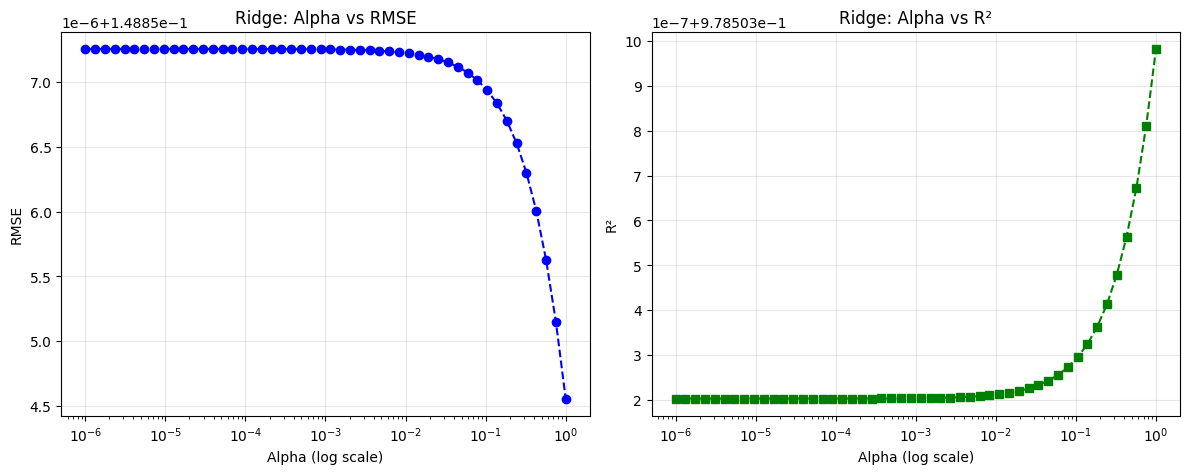

In [68]:
# Copies of preprocessed datasets
X_train_alpha = X_train_p.copy()
X_val_alpha = X_val_p.copy()

y_train_alpha = y_train_p.copy()
y_val_alpha = y_val_p.copy()


# Candidate alph avalues (controls strength of L2 regularization)
alphas=np.logspace(-6, 0, 50)   # Creates 50 values between 1e-06 and 1

# Create empty lists to store the avg. cross-validation RMSE and R² computed for each alpha
rmse_scores = []
r2_scores =[]


# Use the same 5-folds for evey alpha
cv = KFold(n_splits=5, shuffle=True, random_state=42)

for alpha in alphas:
  ridge = Ridge(alpha=alpha)

  # Generate predictions for hold out (unseen) observations
  y_pred_alpha = cross_val_predict(ridge, X_train_alpha, y_train_alpha, cv=cv)

  # Compute metrics
  rmse_alpha = np.sqrt(mean_squared_error(y_train_alpha, y_pred_alpha))
  r2_alpha = r2_score(y_train_alpha, y_pred_alpha)

  rmse_scores.append(rmse_alpha)
  r2_scores.append(r2_alpha)

# Plot RMSE and R² against alpha

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(alphas, rmse_scores, marker='o', linestyle='--', color='b')
axes[0].set_xscale('log')
axes[0].set_xlabel('Alpha (log scale)')
axes[0].set_ylabel('RMSE')
axes[0].set_title('Ridge: Alpha vs RMSE')
axes[0].grid(True, alpha=0.3)

axes[1].plot(alphas, r2_scores, marker='s', linestyle='--', color='g')
axes[1].set_xscale('log')
axes[1].set_xlabel('Alpha (log scale)')
axes[1].set_ylabel('R²')
axes[1].set_title('Ridge: Alpha vs R²')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

<font color=royalblue>The Ridge regression model was relatively insensitive to the choice of the regularisation parameter α</font>. Across the evaluated range, RMSE varied only from approximately 0.1488545 to 0.1488573, while R² ranged from 0.9785002 to 0.9785010. Since both metrics changed only in the sixth and seventh decimal places, regularisation had a negligible impact on predictive performance, indicating that the model is inherently stable and does not appear to suffer materially from overfitting.

The minimal variation in RMSE and R² across different alpha values suggests that <b>the model is stable and generalises effectively to unseen data</b>, with no clear indication of excessive fitting to the training dataset.

##### <font color=#008B8B><b>7.2.2.2.2 Ridge Coefficient Analysis</b>

The Ridge Regression model is trained using the optimal regularization strength selected by `RidgeCV(α = 1)`.

Model performance is evaluated using the established evaluation framework on the training and validation sets. The fitted coefficients are then examined to identify which predictors have the largest estimated associations with the log-transformed `price` and to compare the coefficient pattern with that of the baseline Linear Regression model.

In [69]:
# Train Ridge Regression Model Using Optimal Alpha

# Build a Ridge regression model with the optimal alpha
ridge_model = Ridge(alpha=optimal_alpha)
ridge_model.fit(X_train_lr, y_train_lr)

# Evaluate Ridge model performance on train and validation sets
evaluate_model('Ridge Regression',
               ridge_model,
               X_train_lr, X_val_lr,
               y_train_lr, y_val_lr)

# Get the coefficients and reshape to ensure they are 1-dimensional
ridge_coefficients = ridge_model.coef_.ravel()

# Create a DataFrame to display the feature importance
feature_importance_ridge = pd.DataFrame({
    'Feature': X_train_lr.columns,
    'Coefficient': ridge_coefficients
})

# Add absolute coefficient values for ranking
feature_importance_ridge['Absolute Coefficient'] = feature_importance_ridge['Coefficient'].abs()
# Sort the features by importance (largest absolute coefficients first)
feature_importance_ridge = feature_importance_ridge.sort_values(by='Absolute Coefficient', ascending=False).reset_index(drop=True)
feature_importance_ridge

,Feature,Coefficient,Absolute Coefficient
0,length,0.573261,0.573261
1,height,0.403642,0.403642
2,clarity,0.199080,0.199080
3,width,0.161649,0.161649
4,color,0.133418,0.133418
5,carat,-0.043029,0.043029
6,cut,0.026405,0.026405
7,table,0.009036,0.009036


In [70]:
model_comparison_df

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,Baseline Model: Linear Regression,1003.40,1016.70,25.50,0.98,0.98,480.93,185.95
1,Lasso Regression,1009.74,1023.06,25.66,0.98,0.98,482.01,186.20
2,Ridge Regression,1003.56,1016.86,25.50,0.98,0.98,480.89,186.10


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* The Ridge Regression model identified `length` and `height` as the most influential predictors, with coefficients of 0.573 and 0.404 respectively. `clarity`, `width`, and `color` also contributed positively to the prediction. The variables `cut` and `table` exhibited minimal influence, while <b>`carat` showed a small negative coefficient, likely due to multicollinearity with the dimensional features</b>. Overall, the model suggests that the physical dimensions of the diamond are the strongest drivers of the target variable.

* <b>Linear Regression is the preferred model</b> because it achieves essentially the same predictive performance as Ridge and Lasso while remaining the simplest and easiest to interpret. Ridge can be presented as the best regularised alternative, but the improvement is too small to be of practical significance.

* These results suggest that the underlying linear relationship is strong and that regularisation provides only marginal benefits, indicating that <font color=cadetblue>overfitting is not a significant concern for this dataset</font>.



```
      EDA: carat has a strong positive relationship with price
                                  ↓
      VIF analysis: severe multicollinearity among size-related variables
                                  ↓
      Baseline Linear Regression: struggles to assign unique importance to carat versus the dimensional variables.
                                  ↓
      Ridge Regression: reduced coefficient instability caused by multicollinearity, but predictive performance changed little.
                                  ↓
      Multicollinearity primarily affected coefficient interpretation rather than overall model accuracy.
```

#### <font color=darkslategray><u>7.2.2.3 Elastic Net Regression</u></font>

* `Elastic Net` <b>combines L1 and L2 regularization</b>, with their relative contributions controlled by <b>l1_ratio</b>. The <b>alpha</b> parameter controls the overall regularization strength.

* `ElasticNetCV` is used to evaluate different combinations of <font color = #5D3FD3>regularization strength (alpha)</font> and <font color = #5D3FD3>L1/L2 balance</font> and select the combination that provides the lowest cross-validated error.

The selected hyperparameters are then ised to fit the final Elastic Net model, which is evaluated on the training and validation sets.

In [71]:
# Initialize ElasticNetCV to search for the best combination of alpha (regularization strength) and l1_ratio (balance between L1 and L2 penalties)
'''
 We are searching for the best combination of alpha (regularization strength)
 and l1_ratio (balance between L1 and L2 penalties)
 - alpha controls how strongly coefficients are shrunk.
 - l1_ratio = 0   → Pure Ridge (L2)
 - l1_ratio = 1   → Pure Lasso (L1)
 - 0 < l1_ratio < 1 → Elastic Net
'''
elasticnet_cv = ElasticNetCV(
    alphas=np.logspace(-6, 0, 50),                                           # Candidate regularization strengths
    l1_ratio=[0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0],          # Mix of L1/L2 penalties to test
    cv=5,
    random_state=42,
    max_iter=10000,
    tol=0.0001)
# Fit ElasticNetCV on the training data
'''
Internally trains multiple Elastic Net models across all alpha × l1_ratio combinations
and selects the pair that yields the lowest validation error.
'''
elasticnet_cv.fit(X_train_lr, y_train_lr)

# Get the best hyperparameters found during cv (alpha and l1_ratio values)
optimal_alpha = elasticnet_cv.alpha_
optimal_l1_ratio = elasticnet_cv.l1_ratio_

print(f'Optimal alpha: {optimal_alpha}')
print(f'Optimal l1_ratio: {optimal_l1_ratio}')

Optimal alpha: 0.00021209508879201905
Optimal l1_ratio: 0.05


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* Elastic Net selected an optimal l1_ratio of 0.05, indicating that the model relies primarily on Ridge-style regularisation (95%) with only a small contribution from Lasso-style regularisation (5%). This suggests that retaining all predictors with mild coefficient shrinkage is more beneficial than aggressively removing variables, which is consistent with the strong multicollinearity observed among the size-related diamond features.


In [72]:
#Train Elastic Net Regression Model Using Optimal Alpha and L1 Ratio

# Build an ElasticNet regression model with the optimal alpha and l1_ratio
'''
- alpha controls overall regularization strength
- l1_ratio controls the mix of L1 (Lasso) and L2 (Ridge) penalties
'''
elasticnet_model = ElasticNet(alpha=optimal_alpha,
                              l1_ratio=optimal_l1_ratio,
                              random_state = 42,
                              max_iter=10000,
                              tol=0.0001)

# Fit the Elastic Net model on the training data
elasticnet_model.fit(X_train_lr, y_train_lr)

# Evaluate Elastic Net performance on train and validation sets
evaluate_model('Elastic Net Regression',
               elasticnet_model,
               X_train_lr, X_val_lr,
               y_train_lr, y_val_lr)

# Get the coefficients and reshape to ensure they are 1-dimensional
elasticnet_coefficients = elasticnet_model.coef_.ravel()

# Create a DataFrame to display the feature importance
feature_importance_elasticnet = pd.DataFrame({
    'Feature': X_train_lr.columns,
    'Coefficient': elasticnet_coefficients
})

# Add absolute coefficient values for ranking
feature_importance_elasticnet['Absolute Coefficient'] = feature_importance_elasticnet['Coefficient'].abs()
# Sort features by importance (largest absolute coefficients first)
feature_importance_elasticnet = feature_importance_elasticnet.sort_values(by='Absolute Coefficient', ascending=False)

feature_importance_elasticnet

,Feature,Coefficient,Absolute Coefficient
5,length,0.553801,0.553801
7,height,0.400945,0.400945
2,clarity,0.198840,0.198840
6,width,0.179269,0.179269
1,color,0.133420,0.133420
3,carat,-0.038614,0.038614
0,cut,0.026417,0.026417
4,table,0.009045,0.009045


In [73]:
model_comparison_df

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,Baseline Model: Linear Regression,1003.40,1016.70,25.50,0.98,0.98,480.93,185.95
1,Lasso Regression,1009.74,1023.06,25.66,0.98,0.98,482.01,186.20
2,Ridge Regression,1003.56,1016.86,25.50,0.98,0.98,480.89,186.10
3,Elastic Net Regression,1005.45,1018.72,25.55,0.98,0.98,480.93,185.28


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

*  The results for the Elastic Net model are almost equivalent to Ridge Regression and offers no meaningful improvement over the baseline Linear Regression model.


### <b>7.2.3 Linear Regression with Interaction Terms (Polynomial Features)</b>





The previous models assumed that each feature affects diamond price independently. However, <font color=darkblue>the EDA suggested that some features may work together to influence price</font>.

Pairwise interaction terms are introduced using `PolynomialFeatures` with `interaction_only = True`. This allows the model to capture relationships between pairs of features without adding squared terms, providing a test of whether feature interactions can improve predictive performance.

In [74]:
## Train Linear Regression Model on Interaction Features
# Create polynomial interaction features (degree=2)
'''
interaction_only=True → only pairwise interactions, no squared terms
include_bias=False → do not add a constant bias column
'''
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)

# Transform training and validation sets into interaction feature matrices
X_train_poly_arr = poly.fit_transform(X_train_p)
X_val_poly_arr = poly.transform(X_val_p)

y_train_poly = y_train_p.copy()
y_val_poly = y_val_p.copy()

# Retrieve readable feature names for the interaction terms
poly_feature_names = poly.get_feature_names_out(X_train_p.columns)

# Convert transformed arrays into DataFrames for easier inspection
X_train_poly = pd.DataFrame(X_train_poly_arr, columns=poly_feature_names)
X_val_poly = pd.DataFrame(X_val_poly_arr, columns=poly_feature_names)


# Train a standard Linear Regression model on the interaction-only features
lr_model_poly = LinearRegression()
lr_model_poly.fit(X_train_poly, y_train_poly)

# Evaluate model performance on train and validation sets
evaluate_model('Linear Regression with Interactions',
               lr_model_poly,
               X_train_poly, X_val_poly,
               y_train_poly, y_val_poly)

In [75]:
model_comparison_df

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,Baseline Model: Linear Regression,1003.40,1016.70,25.50,0.98,0.98,480.93,185.95
1,Lasso Regression,1009.74,1023.06,25.66,0.98,0.98,482.01,186.20
2,Ridge Regression,1003.56,1016.86,25.50,0.98,0.98,480.89,186.10
3,Elastic Net Regression,1005.45,1018.72,25.55,0.98,0.98,480.93,185.28
4,Linear Regression with Interactions,722.23,743.67,18.65,0.99,0.98,387.46,149.70


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* <b>The Linear Regression with pairwise interactions is now the best performing model</b>. We observe substantial imporvements when compared t the baseline Linear Regression model :
  * Nearly 27% lower RMSE.
  * Almost 20% lower average prediction error.

* The regularisation models did not significantly improve performance suggesting overfitting was not the main problem. Multicollinearity mainly affected coeffient interpretation. So, we did not really need it.

* The interaction model captured relationships between predictors that were not present in the baesline linear specification. This tells us something different: <font color=darkblue>The relationship between predictors and price is not purely additive</font>. The relatively small gap between training and validation performance further indicates that <b>the improvement generalises well and is not simply the result of overfitting</b>.


## <font color=#0000CD>7.3 Tree-Based Ensemble Models

The results from the linear models show that allowing feature interactions can improve price prediction, but `Polynomial Regression` requires these interactions to be created explicitly.

<b>Tree-based models</b> provide a more flexible approach by learning <b> non-linear relationships and feature interactions directly from the data</b>.

This section therefore evaluates <b>tree-based regression models</b> to determine whether they can further improve predictive performance without requiring interaction terms to be manually specified.

### <b>7.3.1 Random Forest Regressor</b>

<b>Random Forest</b> is an ensemble regression method that combines predictions from multiple decision trees. By averaging the predictions across many trees, <font color = #432DD7>it can capture non-linear relationships and feature interactions without requiring them to be explicitly specified</font>.

We evaluate this model to determine whether this increased modelling flexibility will improve price prediction compared with the linear and interaction-based models evaluated previously.

In [76]:
#Train and Evaluate a Random Forest Regressor

# Prepare train/validation sets for Random Forest
X_train_rf = X_train_p.copy()
X_val_rf = X_val_p.copy()

y_train_rf = y_train_p.copy()
y_val_rf = y_val_p.copy()

# Initialize Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
# Train the model
rf_model.fit(X_train_rf, y_train_rf)

# Evaluate model performance on train and validation set
evaluate_model('Random Forest Regressor',
               rf_model,
               X_train_rf, X_val_rf,
               y_train_rf, y_val_rf)

In [77]:
model_comparison_df

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,Baseline Model: Linear Regression,1003.40,1016.70,25.50,0.98,0.98,480.93,185.95
1,Lasso Regression,1009.74,1023.06,25.66,0.98,0.98,482.01,186.20
2,Ridge Regression,1003.56,1016.86,25.50,0.98,0.98,480.89,186.10
3,Elastic Net Regression,1005.45,1018.72,25.55,0.98,0.98,480.93,185.28
4,Linear Regression with Interactions,722.23,743.67,18.65,0.99,0.98,387.46,149.70
5,Random Forest Regressor,207.97,573.75,14.39,1.00,0.99,280.63,102.68


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* The linear, Ridge, Lasso and Elastic Net models exhibited very small differences between training and validation RMSE, indicating strong generalisation and minimal overfitting.

* The interaction model achieved substantially lower errors while maintaining a small train-validation gap, suggesting that the added complexity was beneficial.

* In contrast, the Random Forest model showed a much larger gap between training and validation performance, indicating <b>some degree of overfitting</b>. However, despite this overfitting, <font color = #0047AB>Random Forest achieved the lowest validation RMSE and highest validation R², making it the most accurate model overall</font>.


### <b>7.3.2 Gradient Boosting Regressor</b>

The Random Forest Regressor substantially improved predictive performance compared with the linear and interaction-based models. The next tree-based approach evaluated is <b>Gradient Boosting</b>, which <b>builds an ensemble of decision trees sequentially rather than independently</b>.

<font color=#052F4A>In Gradient Boosting, each successive tree is trained to improve upon the errors made by the existing ensemble. This sequential learning process allows the model to progressively refine its predictions and capture complex relationships between the predictors.</font>

Gradient Boosting is therefore evaluated to determine whether this sequential approach can further improve `price` prediction compared to the Random Forest model.

In [78]:
# Train Gradient Boosting Regressor

# Prepare train and validation sets for Gradient Boosting
X_train_gbr = X_train_p.copy()
X_val_gbr = X_val_p.copy()

y_train_gbr = y_train_p.copy()
y_val_gbr = y_val_p.copy()

# Initialize Gradient Boosting Regressor
gbr_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
# Train the model
gbr_model.fit(X_train_gbr, y_train_gbr)

# Evaluate model performance on train and validation set
evaluate_model('Gradient Boosting Regressor',
               gbr_model,
               X_train_gbr, X_val_gbr,
               y_train_gbr, y_val_gbr)

In [79]:
model_comparison_df

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,Baseline Model: Linear Regression,1003.40,1016.70,25.50,0.98,0.98,480.93,185.95
1,Lasso Regression,1009.74,1023.06,25.66,0.98,0.98,482.01,186.20
2,Ridge Regression,1003.56,1016.86,25.50,0.98,0.98,480.89,186.10
3,Elastic Net Regression,1005.45,1018.72,25.55,0.98,0.98,480.93,185.28
4,Linear Regression with Interactions,722.23,743.67,18.65,0.99,0.98,387.46,149.70
5,Random Forest Regressor,207.97,573.75,14.39,1.00,0.99,280.63,102.68
6,Gradient Boosting Regressor,596.11,634.50,15.91,0.99,0.99,323.03,124.24


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* Random Forest still remains the better performing tree-based model on RMSE</b>.

* While Gradient boosting underperforms Random Forest on the selected error metrics, it has an interesting characteristic: its train/validation performance is much closer: Random Forest is more accurate but Gradient Boosting has less train-to-validation seperation.

### <b>7.3.3 XGBoost Regressor</b>

Building on the success of ensemble methods like <b>Random Forest</b> and <b>Gradient Boosting</b>, we next turn to <b>XGBoost (Extreme Gradient Boosting)</b>.

As a highly optimized and scalable implementation of gradient boosting, <font color=#0818A8><b>XGBoost</b> is renowned for its <font color=	#0818A8>superior performance</font>, <font color=	#0818A8>speed</font>, and <font color=	#0818A8>advanced regularization capabilities</font> (fit the training data well while keeping the model simple)</font>. Implementing it is a crucial step towards potentially achieving the highest possible predictive accuracy for our diamond pricing model.

In [80]:
# Train XGBoost Regressor

# Prepare train/validation/validation sets for XGBoost
X_train_xgb = X_train_p.copy()
X_val_xgb = X_val_p.copy()


y_train_xgb = y_train_p.copy()
y_val_xgb = y_val_p.copy()


# Initialize XGBoost Regressor
xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)

# Train the model
xgb_model.fit(X_train_xgb, y_train_xgb)

# Evaluate model performance on train, validation, and validation sets
evaluate_model('XGBoost (Extreme Gradient Boosting) Regressor',
               xgb_model,
               X_train_xgb, X_val_xgb,
               y_train_xgb, y_val_xgb)

In [81]:
model_comparison_df

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,Baseline Model: Linear Regression,1003.40,1016.70,25.50,0.98,0.98,480.93,185.95
1,Lasso Regression,1009.74,1023.06,25.66,0.98,0.98,482.01,186.20
2,Ridge Regression,1003.56,1016.86,25.50,0.98,0.98,480.89,186.10
3,Elastic Net Regression,1005.45,1018.72,25.55,0.98,0.98,480.93,185.28
4,Linear Regression with Interactions,722.23,743.67,18.65,0.99,0.98,387.46,149.70
5,Random Forest Regressor,207.97,573.75,14.39,1.00,0.99,280.63,102.68
6,Gradient Boosting Regressor,596.11,634.50,15.91,0.99,0.99,323.03,124.24
7,XGBoost (Extreme Gradient Boosting) Regressor,491.09,552.97,13.87,0.99,0.99,278.50,102.08


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* The train-validation performance gap provides an indication of model generalisation. The linear, Ridge, Lasso and Elastic Net models exhibited very small RMSE gaps (approximately 13 points), suggesting minimal overfitting but also relatively limited predictive flexibility.

* Introducing interaction terms substantially improved accuracy while maintaining a small gap, indicating good generalisation.

* Tree-based ensemble methods achieved the strongest predictive performance overall. Random Forest displayed the largest train-validation gap, suggesting a higher degree of overfitting, whereas Gradient Boosting and XGBoost achieved a better balance between model complexity and generalisation.

* Among all models, <b>XGBoost delivered the lowest validation RMSE (\$552.97) and MAE (\$278.50), making it the best-performing model despite a moderate increase in the train-validation gap</b>.

# <u><font color=#000080>8. Feature Importance and Feature Selection</font></u>

This section examines <b>which features contribute most to the predictions of the best performing XGBoost Regressor</b> and <font color=#1434A4> whether similar predictive performance can be achieved using a reduced set of predictors</font>.

Feature importance techniques are used to identify the variables that contribute most to model predictions, while feature selection experiments evaluate the impact of removing potentially redundant features. These analyses build on the earlier exploratory and correlation analyses , which revealed strong relationships among  several size-related variables.

The objective is to determine whether all predictors are neccessary for accurate predictions or whether a simpler model can achieve comparable performance using fewer features.

## <font color=#0000CD>8.1 XGBoost Built-In Feature Importance </font>



XGBoost provides built-in feature importance scores that <font color=	#3F00FF>rank predictors according to their contribution to the model</font>. These scores provide an initial indication of which variables the XGBoost Regressor model relies on most when predicting diamond `prices`.

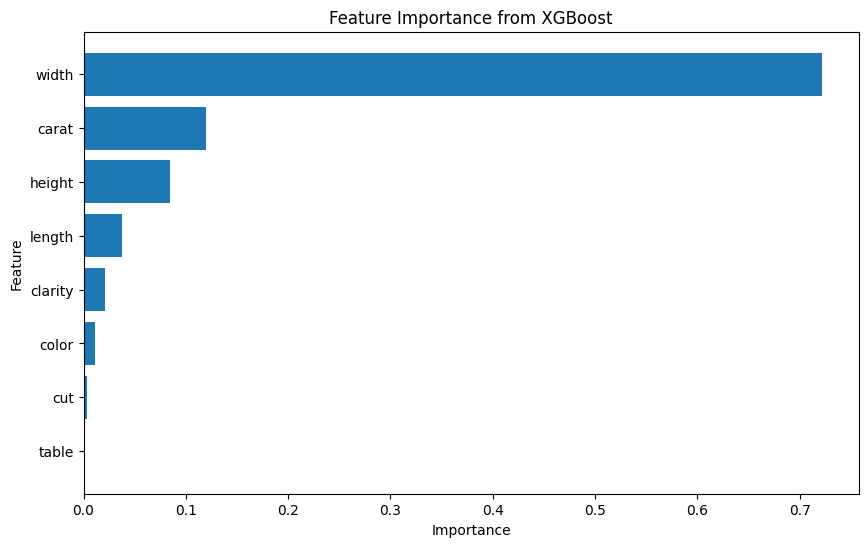

,Feature,Importance
6,width,0.721374
3,carat,0.120046
7,height,0.084321
5,length,0.037973
2,clarity,0.021344
1,color,0.011619
0,cut,0.002922
4,table,0.000401


In [82]:
# Compute and Plot XGBoost Feature Importance

# Get feature importance scores from XGBoost model
feature_importances = xgb_model.feature_importances_
feature_names = X_train_xgb.columns

# Create a DataFrame for feature importance
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
})

# Sort by importance (descending)
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance from XGBoost')
plt.gca().invert_yaxis()
plt.show()

importance_df

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* `width`, `carat` and `length` have the highest built-in importance scores, consistent with the strong relationships between diamond size and price identified during EDA.

* `clarity`and `height`have lower scores, followed by `color`, while `cut` and `table` have the lowest scores.

* The size-related predictors are strongly correlated , these scores should not be interpreted as individual, independent feature effects.

* The five highest ranked features are selected for a reduced-feature experiment to test whether predictive performance can be maintained with fewer predictors.

## <font color=#0000CD>8.2 SHAP Analysis</font>

While the built-in XGBoost feature importance provides an overall ranking of predictorsbut does not really fully explain how feature values influence individual predictions. SHAP (SHapley Additive exPlanations) complements this ranking by estimating each feature's contribution to the model output.

The analysis examines both the <b>magnitude</b> and <b>direction</b> of feature contributions, providing further insight into the patterns learned by the XGBoost Regressor.

<font color=#0000cd>Because the model was trained on log-transformed prices, SHAP values explain contributions to the model's log-transformed output rather than directly to prices in dollars</font>.


### <b>8.2.1 SHAP Summary Plot (Beeswarm)</b>

<i> How did features contribute across observations?</i>









The SHAP summary plot extends the built-in importance ranking by showing how feature values influence predictions across individual observations. It displays both the distribution and direction of SHAP contributions, helping to reveal how the model uses each predictor.

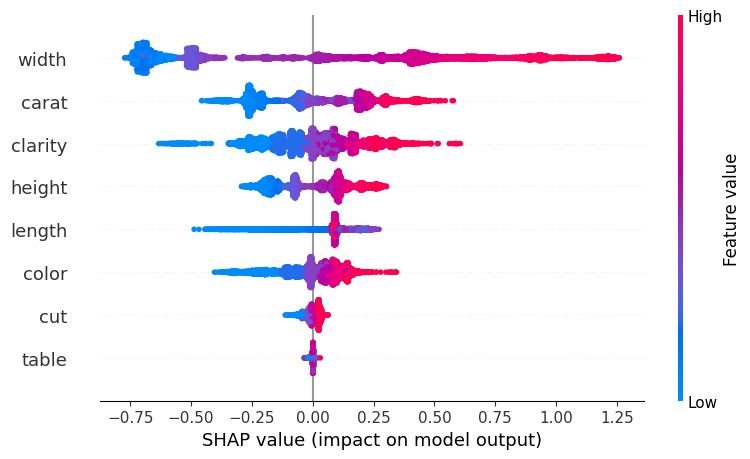

In [83]:
## Create SHAP explainer
explainer = shap.TreeExplainer(xgb_model)

## Compute SHAP values for validation data
shap_values = explainer.shap_values(X_val_xgb)

## Detailed beeswarm plot (shows distribution of impact per feature)
shap.summary_plot(shap_values, X_val_xgb)


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* `width`, `carat`, and `length` show the broadest distributions of SHAP values, indicating that their contributions vary substantially across observations. Higher values generally correspond to positive SHAP contributions, while lower values tend to correspond to negative SHAP values.

* `clarity` has both positive and negative SHAP values, showing its contribution varies across observations.

* `height` and `color` also influence predictions with smaller contributions compared to the leading size-related features.

* SHAP values for `cut` and `table` are concentrated close to zero providing the smallest contributions to the model output in this analysis.

Overall, SHAP reinforces the importance of size-related features, followed by `clarity` and `color`, while suggesting that `cut` and `table` have comparatively smaller contributions.



## <font color=#0000CD>8.3 Feature Reduction Experiments</font>


### <b>8.3.1 Top 5 Features Only </b>

The built-in XGBoost feature-importance scores identified `width`, `carat`, `height`,`length`, and `clarity` as the five highest ranked predictors.To test whether the lower ranked features can be removed without substantially reducing predictive performance, a reduced feature XGBoost model is trained using only these five predictors.

The experiment uses the same basic XBGoost settings as the original model,  allowing the effect of reducing the feature set to be assessed across the model comparison metrics.


In [84]:
# Select Top 5 Features and Retrain Optimized XGBoost

print(f'XGBoost Regressor + Top 5 Features w.r.t Importance score')
print('---------------------------------------------------------------------')

# Extract top 5 features
selected_features = importance_df['Feature'].head(5).tolist()
print(f'Selected Features: {selected_features}')

# Prepare Reduced Feature Dataset
X_train_selected = X_train_xgb[selected_features]
X_val_selected = X_val_xgb[selected_features]

y_train_selected = y_train_xgb.copy()
y_val_selected = y_val_xgb.copy()

# Train a new XGBoost model using only the top 5 features
xgb_top5_model = xgb.XGBRegressor(
      n_estimators=100,
      learning_rate=0.1,
      random_state=42
)
xgb_top5_model.fit(X_train_selected, y_train_selected)

# Evaluate Reduced‑Feature Model
evaluate_model('XGBoost + Top 5 Features',
                xgb_top5_model,
                X_train_selected, X_val_selected,
                y_train_selected, y_val_selected)


XGBoost Regressor + Top 5 Features w.r.t Importance score
---------------------------------------------------------------------
Selected Features: ['width', 'carat', 'height', 'length', 'clarity']


In [85]:
model_comparison_df

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,Baseline Model: Linear Regression,1003.40,1016.70,25.50,0.98,0.98,480.93,185.95
1,Lasso Regression,1009.74,1023.06,25.66,0.98,0.98,482.01,186.20
2,Ridge Regression,1003.56,1016.86,25.50,0.98,0.98,480.89,186.10
3,Elastic Net Regression,1005.45,1018.72,25.55,0.98,0.98,480.93,185.28
4,Linear Regression with Interactions,722.23,743.67,18.65,0.99,0.98,387.46,149.70
5,Random Forest Regressor,207.97,573.75,14.39,1.00,0.99,280.63,102.68
6,Gradient Boosting Regressor,596.11,634.50,15.91,0.99,0.99,323.03,124.24
7,XGBoost (Extreme Gradient Boosting) Regressor,491.09,552.97,13.87,0.99,0.99,278.50,102.08
8,XGBoost + Top 5 Features,911.40,998.52,25.04,0.98,0.98,532.59,186.93


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* <b>Reducing the feature set from eight to five predictors substantially worsens validation performance</b>. RMSE increases from \$552.97 for the original XGBoost model to \$998.52 for the top-five-feature model.

* The reduced model also has a higher validation MedAE (\$186.93 versus \$102.08), indicating that its typical absolute prediction error increases.

* The five highest ranked features alone do not capture enough predictive information to maintain or improve the orginal model's performance. <font color=#004F98>The lower ranked features collectively provide useful additional information</font>.

* The full feature set is therefore retained for the final model.

### <b>8.3.2 Removing Size-Related Features</b>

The earlier correlation analysis identified strong relationships among `width`, `length` and `height`, suggesting that these physical dimensions contain overlapping information.

To assess their combined contribution, a reduced XGBoost model is trained after removing these three features <b>while retaining carat as the remaining size-related predictor</b>. The results are compared with the original XGBoost model to determine how removing the physical dimensions affects validation performance.

In [86]:
# Create copies of the original training and validation sets
X_train_red = X_train_xgb.copy()
X_val_red = X_val_xgb.copy()

y_train_red = y_train_xgb.copy()
y_val_red= y_val_xgb.copy()


features_to_remove = ['height', 'width', 'length']

# Drop size_related features from training and validation sets
X_train_red = X_train_red.drop(columns=features_to_remove)
X_val_red  = X_val_red.drop(columns=features_to_remove)


print(f"Features remaining : {X_train_red.columns.tolist()}")

# Train a NEW XGBoost model using the reduced feature set
xgb_no_size_model = xgb.XGBRegressor(
      n_estimators=100,
      learning_rate=0.1,
      random_state=42
)

xgb_no_size_model.fit(X_train_red, y_train_red)

# Evaluate the  model
evaluate_model('XGBoost (Remove size-related Features)',
               xgb_no_size_model,
               X_train_red, X_val_red,
               y_train_red, y_val_red)

Features remaining : ['cut', 'color', 'clarity', 'carat', 'table']


In [87]:
model_comparison_df

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,Baseline Model: Linear Regression,1003.40,1016.70,25.50,0.98,0.98,480.93,185.95
1,Lasso Regression,1009.74,1023.06,25.66,0.98,0.98,482.01,186.20
2,Ridge Regression,1003.56,1016.86,25.50,0.98,0.98,480.89,186.10
3,Elastic Net Regression,1005.45,1018.72,25.55,0.98,0.98,480.93,185.28
4,Linear Regression with Interactions,722.23,743.67,18.65,0.99,0.98,387.46,149.70
5,Random Forest Regressor,207.97,573.75,14.39,1.00,0.99,280.63,102.68
6,Gradient Boosting Regressor,596.11,634.50,15.91,0.99,0.99,323.03,124.24
7,XGBoost (Extreme Gradient Boosting) Regressor,491.09,552.97,13.87,0.99,0.99,278.50,102.08
8,XGBoost + Top 5 Features,911.40,998.52,25.04,0.98,0.98,532.59,186.93
9,XGBoost (Remove size-related Features),501.46,544.79,13.66,0.99,0.99,282.00,112.01


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* Removing `width`, `length` and `height` reduces validation RMSE from \$552.97 to \$544.79, a modest improvement of approximately 1.5% over the original XGBoost model.



### <b>8.3.3 Removing Lowest-Ranked SHAP Features</b>





The SHAP analysis indicates that `cut` and `table` make comparatively small contributions to the model output. To evaluate whether these features can be removed, a reduced XGBoost model is trained using the remaining six predictors.

The model is compared with the original XGBoost model using the same basic settings and validation metrics. This experiment assesses whether removing the lowest-ranked SHAP features maintains predictive performance.

In [88]:
# SHAP-Based Feature Reduction for XGBoost

# Create copies of the original training and test sets
X_train_shap = X_train_xgb.copy()
X_val_shap = X_val_xgb.copy()

y_train_shap = y_train_xgb.copy()
y_val_shap = y_val_xgb.copy()

# List features to remove based on SHAP analysis
'''
Features identified as low-impact from SHAP analysis
These contributed very little to model predictions and
removing them may reduce noise and improve generalization.
'''
features_to_remove = ['cut', 'table']

# Drop low-impact features from training and validation sets
X_train_shap = X_train_shap.drop(columns=features_to_remove)
X_val_shap= X_val_shap.drop(columns=features_to_remove)


print(f"Features remaining in X_train_shap: {X_train_shap.columns.tolist()}")

# Train a NEW XGBoost model using the reduced feature set
xgb_shap_model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

xgb_shap_model.fit(X_train_shap, y_train_shap)

# Evaluate the SHAP-optimized model
evaluate_model('XGBoost (Remove lowest rank shap Features)',
               xgb_shap_model,
               X_train_shap, X_val_shap,
               y_train_shap, y_val_shap)



Features remaining in X_train_shap: ['color', 'clarity', 'carat', 'length', 'width', 'height']


In [89]:
model_comparison_df

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,Baseline Model: Linear Regression,1003.40,1016.70,25.50,0.98,0.98,480.93,185.95
1,Lasso Regression,1009.74,1023.06,25.66,0.98,0.98,482.01,186.20
2,Ridge Regression,1003.56,1016.86,25.50,0.98,0.98,480.89,186.10
3,Elastic Net Regression,1005.45,1018.72,25.55,0.98,0.98,480.93,185.28
4,Linear Regression with Interactions,722.23,743.67,18.65,0.99,0.98,387.46,149.70
5,Random Forest Regressor,207.97,573.75,14.39,1.00,0.99,280.63,102.68
6,Gradient Boosting Regressor,596.11,634.50,15.91,0.99,0.99,323.03,124.24
7,XGBoost (Extreme Gradient Boosting) Regressor,491.09,552.97,13.87,0.99,0.99,278.50,102.08
8,XGBoost + Top 5 Features,911.40,998.52,25.04,0.98,0.98,532.59,186.93
9,XGBoost (Remove size-related Features),501.46,544.79,13.66,0.99,0.99,282.00,112.01


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* Removing `cut` and `table` increases validation RMSE from \$552.97 to \$563.53, indicating a modest decline in predictive performance.

* Validation MAE increases from \$278.50 to \$288.93, while MedAE rises from \$102.08 to \$108.42.

* Although SHAP suggests that `cut` and `table` have relatively small contributions, removing them reduces the model's predictive performance. <b>Their combined contribution therefore appears useful, even if it is smaller than that of the leading features</b>.

<font color=#4682B4> The full feature set is retained because it achieves better validation performance than this reduced-feature model</font>.

# <u><font color=#000080>9. Model Optimization</font></u>

The model comparison in Section 7 identified XGBoost as the strongest-performing model among the original models evaluated. Section 8 then examined its feature contributions and tested whether reducing the feature set could maintain predictive performance.

<b>This section uses Bayesian optimization with Optuna to tune XGBoost's hyperparameters</b>, followed by residual analysis and a final comparison of validation results. The selected model is then evaluated on the held-out test set to assess its performance on unseen data.

## <font color=#0000CD>9.1 Hyperparameter Tuning: Bayesian Optimization</font>


<font color= #0F52BA>Bayesian optimization provides a systematic approach to hyperparameter tuning by using the results of previous trials to guide subsequent searches</font>.

In this project, <b>Optuna's Tree-structured Parzen Estimator (TPE) sampler</b>explores XGBoost hyperparameters controlling <b>tree complexity</b>, <b>learning rate</b>, <b>sampling and regularization</b>. Each trial is evaluated using RMSE on the validation set, calculated on the original price scale after converting predictions back from the log scale.

<b>The objective is to identify a parameter configuration that reduces prediction error while retaining the full feature set</b>.

In [90]:
# Hyperparameter Tuning with Bayesian Optimization (Optuna + XGBoost)
def objective(trial):
  # Hyperparameter search space for XGBoost
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0), # L1 regularization
        'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 1.0) # L2 regularization
    }

    # Instantiate XGBoost model with suggested parameters
    model = xgb.XGBRegressor(**param, random_state=42, n_jobs=-1)

    #Fit the model (target is log-transformed)
    model.fit(X_train_xgb, y_train_xgb)

    # Predict on the validation set (predictions are in log scale)
    y_pred_log = model.predict(X_val_xgb)

    '''
    CRITICAL for Optuna objective: Convert predictions AND true values back to original scale
    Optuna must minimize RMSE in real-world dollar terms
    '''
    y_pred_orig = np.expm1(y_pred_log)
    y_val_orig = np.expm1(y_val_xgb) # y_val_xgb is log-transformed, need to inverse transform it

    # Compute RMSE on the original scale
    rmse = np.sqrt(mean_squared_error(y_val_orig, y_pred_orig))

    return rmse


In [91]:
# Run Bayesian Optimization Study (Optuna + XGBoost)
optuna.logging.set_verbosity(optuna.logging.WARNING) # suppress per-trial logs
study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=100)

# Return best hyperparameters
print("\n--- Optuna Optimization Complete ---")
print("Best RMSE(validation):", study.best_value)
print("Best parameters:", study.best_trial.params)


--- Optuna Optimization Complete ---
Best RMSE(validation): 532.4648256407966
Best parameters: {'n_estimators': 756, 'max_depth': 7, 'learning_rate': 0.045053126207160246, 'subsample': 0.9519204407947159, 'colsample_bytree': 0.8071927037847862, 'min_child_weight': 7, 'reg_alpha': 0.3346650667042362, 'reg_lambda': 0.19685043211823494}


In [92]:
# Train XGBoost model using the best hyperparameters discovered by Optuna
xgb_best_model = xgb.XGBRegressor(**study.best_trial.params, random_state=42, n_jobs=-1)

# Fit the optimized model on the training data (log-transformed target)
xgb_best_model.fit(X_train_xgb, y_train_xgb)

# Evaluate optimized XGBoost on train and validation sets
evaluate_model('XGBoost Regressor (Optimized)',
               xgb_best_model,
               X_train_xgb, X_val_xgb,
               y_train_xgb, y_val_xgb)

In [93]:
model_comparison_df

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,Baseline Model: Linear Regression,1003.40,1016.70,25.50,0.98,0.98,480.93,185.95
1,Lasso Regression,1009.74,1023.06,25.66,0.98,0.98,482.01,186.20
2,Ridge Regression,1003.56,1016.86,25.50,0.98,0.98,480.89,186.10
3,Elastic Net Regression,1005.45,1018.72,25.55,0.98,0.98,480.93,185.28
4,Linear Regression with Interactions,722.23,743.67,18.65,0.99,0.98,387.46,149.70
5,Random Forest Regressor,207.97,573.75,14.39,1.00,0.99,280.63,102.68
6,Gradient Boosting Regressor,596.11,634.50,15.91,0.99,0.99,323.03,124.24
7,XGBoost (Extreme Gradient Boosting) Regressor,491.09,552.97,13.87,0.99,0.99,278.50,102.08
8,XGBoost + Top 5 Features,911.40,998.52,25.04,0.98,0.98,532.59,186.93
9,XGBoost (Remove size-related Features),501.46,544.79,13.66,0.99,0.99,282.00,112.01


<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* Bayesian optimization identifies the Optimized XGBoost Regressor as the best-performing model in the validation comparison, achieving an RMSE of \$532.46 and an MAE of \$264.45.

* Its validation MedAE is \$94.45, meaning that <font color=#00356B>half of the absolute prediction errors are no greater than approximately \$94.45</font>.

* Compared with the original XGBoost model, <b>validation RMSE</b> decreases from \$552.97 to \$532.46, <b>an improvement of approximately 3.7%</b>.

* <font color=#000080>The optimized model outperforms the other evaluated models on validation RMSE, including the reduced-feature variants</font>. The full feature set is therefore retained for the final evaluation.

## <font color=#0000CD>9.2 Final Model Residual Analysis</font>

<b>The validation comparison identifies the Optimized XGBoost Regressor as the preferred model</b>. Before evaluating its final performance on the held-out test set, residual analysis is used to examine the distribution of its prediction errors on the validation set.

<font color=#1D2951><i>The analysis investigates whether residuals are centered around zero, whether systematic patterns remain, and whether the magnitude of errors changes with predicted price</i></font>.

Residuals are examined on both the log-transformed scale, on which the model was trained, and the original price scale, where errors have direct practical meaning.

### <b>9.2.1 Residual Analysis on the Log Scale </b>

These plots show how well the model fits the log‑transformed target.
If residuals are centered around zero with no clear pattern, the model is behaving well in the transformed domain.

In [94]:
# Compute Predictions and Residuals

# Log-scale predictions from optimized XGBoost
y_pred_log_opt = xgb_best_model.predict(X_val_xgb)

# Convert predictions and actuals back to original scale
y_pred_orig_opt = np.expm1(y_pred_log_opt)
y_val_orig_opt = np.expm1(y_val_xgb)

# Residuals on original scale
residuals_orig_opt = y_val_orig_opt - y_pred_orig_opt

# Residuals on log scale
residuals_log_opt = y_val_xgb - y_pred_log_opt

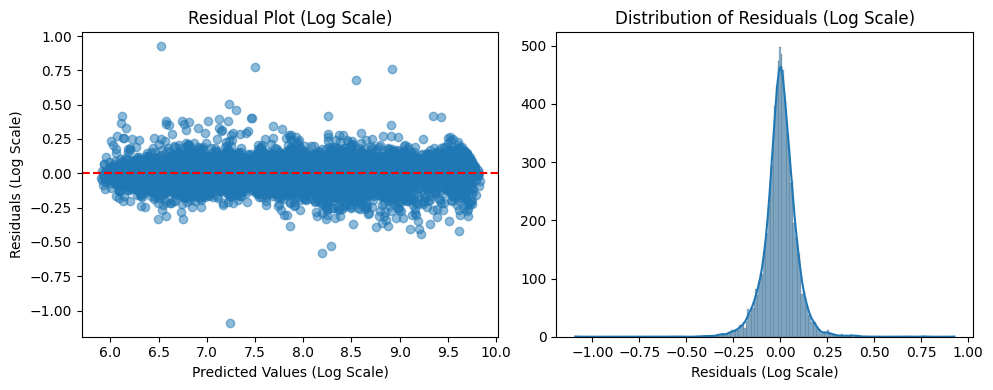

In [95]:
# Plot Log‑Scale Residuals

# Create subplots 1 row 2 columns
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# 1. Residuals vs Predicted (Log Scale)
axs[0].scatter(y_pred_log_opt, residuals_log_opt, alpha=0.5)
axs[0].axhline(y=0, color='r', linestyle='--')
axs[0].set_xlabel('Predicted Values (Log Scale)')
axs[0].set_ylabel('Residuals (Log Scale)')
axs[0].set_title('Residual Plot (Log Scale)')

# 2. Residual distribution (Log Scale)
sns.histplot(residuals_log_opt, kde=True, ax=axs[1])
axs[1].set_title('Distribution of Residuals (Log Scale)')
axs[1].set_xlabel('Residuals (Log Scale)')
axs[1].set_ylabel('')

plt.tight_layout()
plt.show()

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* The log-scale <font color=#10598A>residuals are generally distributed around zero</font> with <b>no obvious systematic pattern across the range of predicted values</b>. This suggests that the Optimized XGBoost model does not exhibit a strong systematic bias in the transformed target space.

* The residual distribution is concentrated around zero, although some observations show larger positive or negative residuals. These represent cases where the model's prediction differs more substantially from the actual transformed price.

* Because there is no evidence of a strong systematic trend in the transformed space <b>the model is able to capture the main relationships between the predictors and the log-transformed target</b>.

* The log-scale analysis is useful for assessing the behaviour of the model in the space in which it was trained, but the practical magnitude of prediction errors is better understood on the original dollar scale.

### <b>9.2.2 Residual Analyis on the Original Price Scale</b>



This is the most important residual view for practical interpretation:

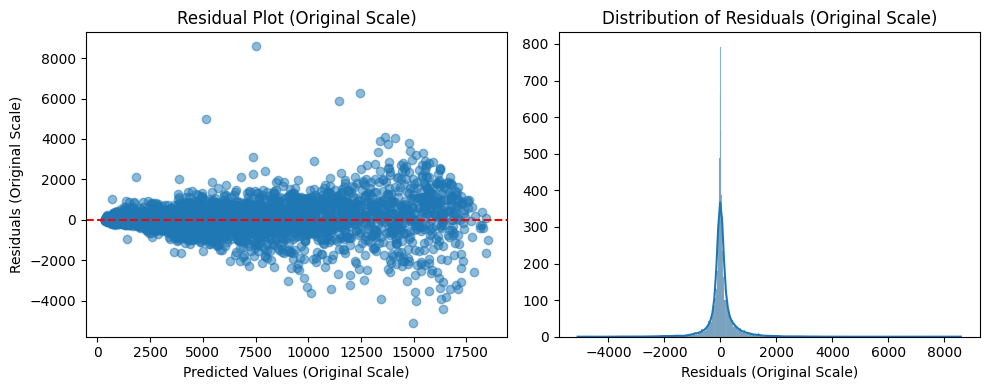

In [96]:
# Plot Residuals on Original Scale

# Create subplots 1 row 2 columns
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# 1. Residuals vs Predicted (Original Scale)
axs[0].scatter(y_pred_orig_opt, residuals_orig_opt, alpha=0.5)
axs[0].axhline(y=0, color='r', linestyle='--')
axs[0].set_xlabel('Predicted Values (Original Scale)')
axs[0].set_ylabel('Residuals (Original Scale)')
axs[0].set_title('Residual Plot (Original Scale)')

# 2. Residual distribution (Original Scale)
sns.histplot(residuals_orig_opt, kde=True, ax=axs[1])
axs[1].set_title('Distribution of Residuals (Original Scale)')
axs[1].set_xlabel('Residuals (Original Scale)')
axs[1].set_ylabel('')

plt.tight_layout()
plt.show()

<font size=4, color=#4169E1>💎<b>OBSERVATIONS</b></font>

* On the original price scale , residuals remain broadly centered around zero, indicating that the model does not show an obvious systematic tendency to consistently overpredict or underpredict across the validation set.

* The spread of residuals increase as predicted price increases, indicating heteroscedasticity. In practical terms, the absolute size of prediction errors tends to become larger for high-priced diamonds.

* This behaviour helps explain why the model's <b>val RMSE of \$532.46</b> is substantially larger than its <b>MedAE of \$94.45</b>. The median absolute error represents the typical test observation, while larger errors from a smaller number of observations have a stronger influence on RMSE.

* The residual analysis therefore shows that <font color=#2C3863><b>the Optimized XGBoost model performs well for the majority of observations, while prediction uncertainty in absolute dollar terms becomes greater for higher-priced diamonds</b></font>.

* These results complement the overall performance metrics from Section 8.1: <b>the model achieves the strongest predictive performance in the model comparison, but its errors are not uniform across the full price range</b>.

## <font color=#0000CD>9.3 Final comparison and Test Evaluation</font>

In [97]:
# 9.4 Final Comparison and Test Evaluation

# ---- 1. Final comparison table (validation set only) ----
'''
All models are ranked on the VALIDATION set. The test set is not used for choosing a model.
'''
final_comparison_df = model_comparison_df.sort_values(by='RMSE(val)').reset_index(drop=True)
display(final_comparison_df)

# ---- 2. Final model selection (decided BEFORE looking at the test set) ----
final_model = xgb_best_model
print('Final model: XGBoost Regressor (Optimized), all features')
print(f'Features used: {X_train_xgb.columns.tolist()}')

# ---- 3. Final evaluation: Train vs Validation vs Test ----
'''
The test set is used ONCE, here, to estimate performance on unseen data.
No model or hyperparameter changes are made after this point.
'''
def final_metrics(model, X, y_log):
    # Predictions on the log scale, converted back to dollars
    y_pred_log = model.predict(X)
    y_pred = np.expm1(y_pred_log)
    y_true = np.expm1(y_log)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {
        'RMSE': round(rmse, 2),
        'RMSE (% of mean price)': round(rmse / y_true.mean() * 100, 2),
        'MAE': round(mean_absolute_error(y_true, y_pred), 2),
        'MedAE': round(median_absolute_error(y_true, y_pred), 2),
        'R² (log scale)': round(r2_score(y_log, y_pred_log), 3)
    }

final_results_df = pd.DataFrame({
    'Train': final_metrics(final_model, X_train_xgb, y_train_xgb),
    'Validation': final_metrics(final_model, X_val_xgb, y_val_xgb),
    'Test': final_metrics(final_model, X_test_xgb, y_test_xgb)
})

display(final_results_df)

,Model,RMSE(train),RMSE(val),RMSE(% Mean Price),R²(train),R²(val),MAE(val),MedAE(val)
0,XGBoost Regressor (Optimized),413.29,532.46,13.35,1.00,0.99,264.45,94.45
1,XGBoost (Remove size-related Features),501.46,544.79,13.66,0.99,0.99,282.00,112.01
2,XGBoost (Extreme Gradient Boosting) Regressor,491.09,552.97,13.87,0.99,0.99,278.50,102.08
3,XGBoost (Remove lowest rank shap Features),508.71,563.53,14.13,0.99,0.99,288.93,108.42
4,Random Forest Regressor,207.97,573.75,14.39,1.00,0.99,280.63,102.68
5,Gradient Boosting Regressor,596.11,634.50,15.91,0.99,0.99,323.03,124.24
6,Linear Regression with Interactions,722.23,743.67,18.65,0.99,0.98,387.46,149.70
7,XGBoost + Top 5 Features,911.40,998.52,25.04,0.98,0.98,532.59,186.93
8,Baseline Model: Linear Regression,1003.40,1016.70,25.50,0.98,0.98,480.93,185.95
9,Ridge Regression,1003.56,1016.86,25.50,0.98,0.98,480.89,186.10


Final model: XGBoost Regressor (Optimized), all features
Features used: ['cut', 'color', 'clarity', 'carat', 'table', 'length', 'width', 'height']


,Train,Validation,Test
RMSE,413.290,532.460,522.620
RMSE (% of mean price),10.530,13.350,13.390
MAE,212.600,264.450,262.040
MedAE,80.450,94.450,95.310
R² (log scale),0.995,0.993,0.992


# <u><font color=#000080> 10. Conclusion</font></u>




This project developed and compared regression models to predict diamond prices from cut, color, clarity and physical measurements. Data preparation included removing 148 exact duplicate rows and three rows with impossible dimensions, helping ensure that the analysis was based on valid observations.



## <font color=#0000CD>9.1 Key findings</font>




* <b>Size-related features are the strongest predictors</b>.Carat weight and physical dimensions consistently ranked highly in the exploratory analysis, XGBoost feature importance and SHAP analysis. Clarity and color also contributed to predictions, while cut and table had comparatively smaller contributions.

* <b>Multicollinearity affects linear-model interpretation</b>. The size-related features were strongly correlated, making it difficult to interpret their individual effects in linear regression. Ridge, Lasso and Elastic Net did not materially improve predictive performance over the baseline linear model.

* <b>Non-linear models performed better than linear models</b>. The interaction model improved on baseline linear regression, while tree-based models achieved further reductions in prediction error. This suggests that the relationships between diamond characteristics and price are not adequately captured by a simple linear model.

* <b>Hyperparameter optimization improved XGBoost performance</b>. Optuna reduced validation RMSE from $552.97 for the original XGBoost model to \$532.46 for the Optimized XGBoost Regressor, an improvement of approximately 3.7%.

* <b>Feature reduction did not outperform the optimized full model</b>. Using only the five highest-ranked features substantially worsened performance. Removing the physical dimensions or the two lowest-ranked SHAP features also produced higher validation RMSE than the optimized full-feature model. All eight predictors were therefore retained for the final model.

## <font color=#0000CD>9.2 Final model performance</font>





The Optimized XGBoost Regressor using all eight features was selected based on validation performance and evaluated on the held-out test set.

| Metric | Train | Validation | Test |
|---|---:|---:|---:|
| RMSE | \$413.29 | \$532.46 | \$522.62 |
| RMSE (% of mean price) | 10.53% | 13.35% | 13.39% |
| MAE | \$212.60 | \$264.45 | \$262.04 |
| MedAE | \$80.45 | \$94.45 | \$95.31 |
| R² (log scale) | 0.995 | 0.993 | 0.992 |



The test RMSE of \$522.62 and MAE of \$262.04 indicate the model's average prediction-error magnitude in dollar terms, while the MedAE of \$95.31 shows that half of the absolute test errors are no greater than approximately \$95.31. The log-scale R² of 0.992 indicates a strong fit in the transformed target space.

<font color=#002D62>Test performance is close to validation performance, suggesting that the model generalizes well to the held-out data</font>. However, this result applies to the particular data split and should not be interpreted as a guarantee of performance on every new dataset.

## <font color=#0000CD>9.3 Limitations</font>





* <b>Uneven prediction errors:</b> Residual analysis indicates that absolute errors tend to increase for more expensive diamonds, so predictions are less precise in dollar terms at the upper end of the price range.

* <b>Single data split:</b> Model comparisons rely on one train-validation-test split. Cross-validation could provide a more robust estimate of performance and help determine whether small differences between models are consistent.

* <b>Feature interpretation:</b> Strong correlations among size-related predictors make it difficult to isolate their individual contributions. Feature importance and SHAP values should therefore be interpreted as explanations of model behaviour rather than proof of independent causal effects.

* <b>Validation-based tuning:</b> Hyperparameters were selected using validation performance, so validation metrics are involved in model selection. The held-out test results provide the final evaluation of the selected model.

## <font color=#0000CD>9.4 Possible next steps</font>



* Use cross-validation to assess the stability of model performance.
* Compare alternative encodings for the ordinal categories `cut`, `color` and `clarity`.
* Investigate additional features, such as the length-to-width ratio, if they can be justified by the data.
* Package preprocessing and prediction into a reusable pipeline for consistent future predictions.